# 📊 Statistics for Data Science — Practical Notebook

**Companion to:** `Statistics_Beginner_Notes.md` and `Statistics_Beginner_Slides.html`

**Dataset:** Indian Engineering Student Placement — CGPA, study hours, skills, stress, placement features.

| Section | Topic |
|---|---|
| 0 | Setup & first look at the data |
| 1 | Central tendency — mean, median, mode |
| 2 | Dispersion — range, variance, std dev, IQR |
| 3 | Distributions & skewness |
| 4 | Probability basics (simulation) |
| 5 | Normal & Standard Normal, Z-scores |
| 6 | Sampling techniques + Central Limit Theorem |
| 7 | Hypothesis testing & Z-tests |
| 8 | Solved practice questions |

> 🧪 Look for the **YOUR TURN** cells — try them before reading the solution.

---
## 0. Setup and first look

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt      # seaborn is built on matplotlib - we only use plt for figures/titles
from scipy import stats

sns.set_theme(style="whitegrid", palette="deep")
sns.set_context("notebook", font_scale=1.0)
plt.rcParams["figure.figsize"] = (9, 4.5)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
np.random.seed(42)   # reproducible randomness

BLUE, RED, GREEN, ORANGE = "#1f6feb", "#d1495b", "#2e9e5b", "#e8952f"
print("seaborn", sns.__version__, "| pandas", pd.__version__)


seaborn 0.13.2 | pandas 2.3.3


In [2]:
from pathlib import Path

# works whether you run from the notebook folder or the project root
candidates = [
    Path("../data/indian_engineering_student_placement.csv"),
    Path("Statistics/data/indian_engineering_student_placement.csv"),
    Path("data/indian_engineering_student_placement.csv"),
]
csv_path = next((p for p in candidates if p.exists()), None)
assert csv_path is not None, "CSV not found - update the path below"

df = pd.read_csv(csv_path)
print("Shape:", df.shape)
df.head()

Shape: (5000, 23)


,Student_ID,gender,branch,cgpa,tenth_percentage,twelfth_percentage,backlogs,study_hours_per_day,attendance_percentage,projects_completed,...,aptitude_skill_rating,hackathons_participated,certifications_count,sleep_hours,stress_level,part_time_job,family_income_level,city_tier,internet_access,extracurricular_involvement
0,1,Male,ECE,8.740,74.000,75.000,0,3.800,71.100,7,...,5,4,5,6.500,8,Yes,Medium,Tier 2,Yes,Medium
1,2,Female,ECE,7.800,75.300,69.700,0,6.300,69.500,5,...,3,4,1,7.100,8,Yes,Medium,Tier 3,Yes,Low
2,3,Female,IT,6.950,62.800,68.300,0,1.500,62.500,8,...,4,6,3,6.100,2,No,Low,Tier 2,Yes,High
3,4,Male,ECE,7.460,57.900,51.400,1,4.700,64.600,6,...,4,2,2,7.300,7,No,Medium,Tier 1,Yes,Low
4,5,Male,IT,6.860,61.300,73.500,2,5.200,75.900,3,...,3,2,1,6.000,7,No,Medium,Tier 1,Yes,Medium


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 23 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   Student_ID                   5000 non-null   int64  
 1   gender                       5000 non-null   object 
 2   branch                       5000 non-null   object 
 3   cgpa                         5000 non-null   float64
 4   tenth_percentage             5000 non-null   float64
 5   twelfth_percentage           5000 non-null   float64
 6   backlogs                     5000 non-null   int64  
 7   study_hours_per_day          5000 non-null   float64
 8   attendance_percentage        5000 non-null   float64
 9   projects_completed           5000 non-null   int64  
 10  internships_completed        5000 non-null   int64  
 11  coding_skill_rating          5000 non-null   int64  
 12  communication_skill_rating   5000 non-null   int64  
 13  aptitude_skill_rat

In [4]:
# Split by data type - the type decides which statistic makes sense
num_df = df.select_dtypes(include=["number"])
cat_df = df.select_dtypes(include=["object"])

print("NUMERICAL columns :", list(num_df.columns))
print()
print("CATEGORICAL columns:", list(cat_df.columns))

NUMERICAL columns : ['Student_ID', 'cgpa', 'tenth_percentage', 'twelfth_percentage', 'backlogs', 'study_hours_per_day', 'attendance_percentage', 'projects_completed', 'internships_completed', 'coding_skill_rating', 'communication_skill_rating', 'aptitude_skill_rating', 'hackathons_participated', 'certifications_count', 'sleep_hours', 'stress_level']

CATEGORICAL columns: ['gender', 'branch', 'part_time_job', 'family_income_level', 'city_tier', 'internet_access', 'extracurricular_involvement']


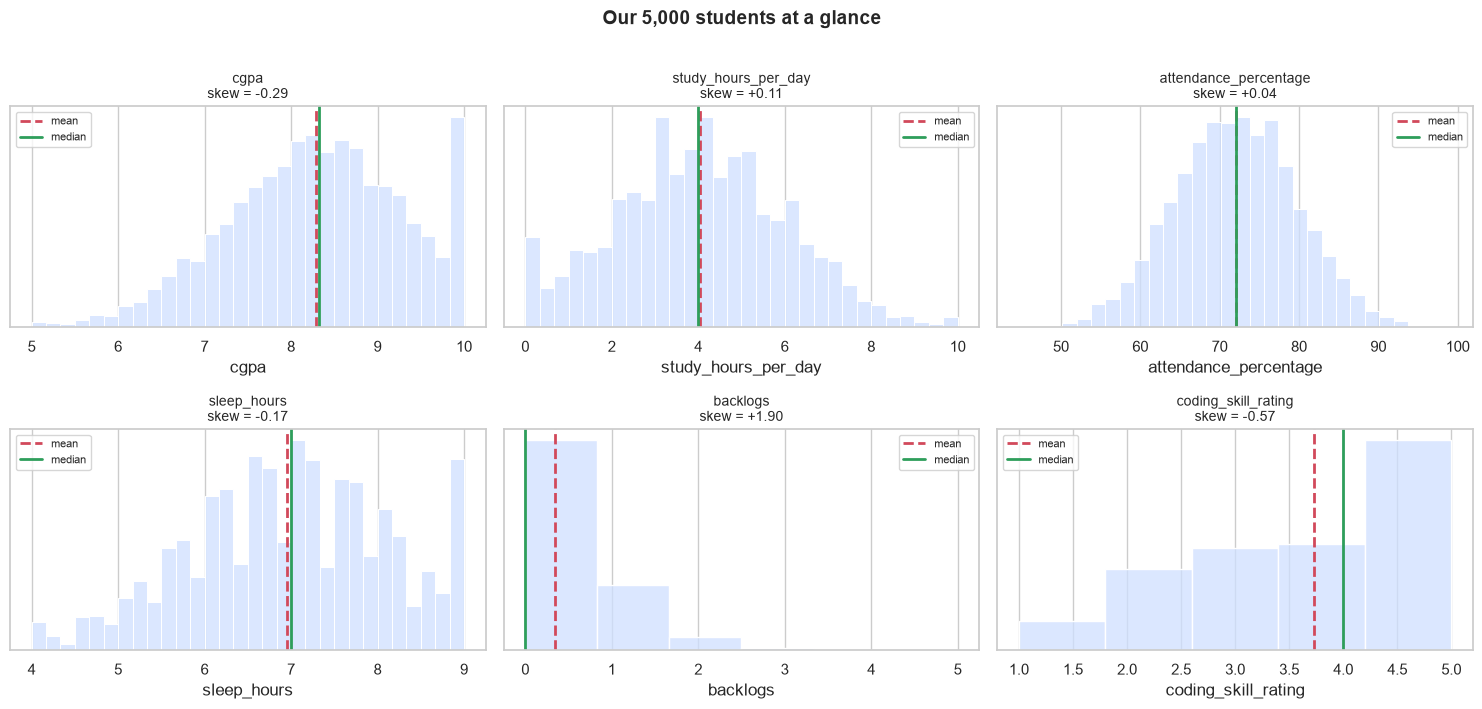

In [5]:
# A quick visual tour of the whole dataset before touching any formula
overview_cols = [c for c in ["cgpa", "study_hours_per_day", "attendance_percentage",
                             "sleep_hours", "backlogs", "coding_skill_rating"] if c in df.columns]

fig, axes = plt.subplots(2, 3, figsize=(15, 7))
for ax, c in zip(axes.ravel(), overview_cols):
    bins = min(30, df[c].nunique())          # discrete columns get one bar per value
    sns.histplot(data=df, x=c, bins=bins, color="#cfe0ff", ax=ax)
    ax.axvline(df[c].mean(), color=RED, ls="--", lw=2, label="mean")
    ax.axvline(df[c].median(), color=GREEN, lw=2, label="median")
    ax.set_title(f"{c}\nskew = {df[c].skew():+.2f}", fontsize=10)
    ax.set_ylabel(""); ax.set_yticks([])
    ax.legend(fontsize=8)
fig.suptitle("Our 5,000 students at a glance", y=1.01, fontsize=14, fontweight="bold")
plt.tight_layout(); plt.show()


> 💡 **Rule:** `mean(branch)` is nonsense. `mode(branch)` is perfect.
> Numerical → mean/median/std. Categorical → mode/value_counts.

---
## 1. Measures of Central Tendency

$$\bar{x}=\frac{\sum x_i}{n}\quad\text{(mean)}\qquad \text{median}=\text{middle value}\qquad \text{mode}=\text{most frequent}$$

In [7]:
col = "cgpa"

print(f"--- {col} ---")
print(f"Mean   : {df[col].mean():.3f}")
print(f"Median : {df[col].median():.3f}")
print(f"Mode   : {df[col].mode().values}")
print(f"Count  : {df[col].count()}")

--- cgpa ---
Mean   : 8.284
Median : 8.320
Mode   : [10.]
Count  : 5000


In [ ]:
# Do it manually so the formula is not a black box
x = df[col].dropna().to_numpy()

manual_mean = x.sum() / len(x)

s = np.sort(x)
n = len(s)
manual_median = s[n // 2] if n % 2 else (s[n // 2 - 1] + s[n // 2]) / 2

print(f"mean = {df[col].mean():.4f}")
print(f"median = {df[col].median():.4f}")

mean = 8.2838
median = 8.3200


In [ ]:
# Central tendency for ALL numeric columns at once
summary = pd.DataFrame({
    "mean":   num_df.mean(),
    "median": num_df.median(),
    "mode":   num_df.mode().iloc[0],
})
summary["mean - median"] = summary["mean"] - summary["median"]
summary.sort_values("mean - median", ascending=False)

,mean,median,mode,mean - median
backlogs,0.344,0.000,0.000,0.344
internships_completed,2.133,2.000,2.000,0.133
aptitude_skill_rating,4.116,4.000,4.000,0.116
study_hours_per_day,4.041,4.000,0.000,0.041
communication_skill_rating,3.025,3.000,4.000,0.025
stress_level,6.020,6.000,10.000,0.020
Student_ID,"2,500.500","2,500.500",1.000,0.000
attendance_percentage,72.042,72.050,68.100,-0.008
cgpa,8.284,8.320,10.000,-0.036
sleep_hours,6.955,7.000,9.000,-0.045


**Reading the table:** a large positive `mean - median` ⇒ **right-skewed** (a few big values pull the mean up).

branch                 -> mode = CSE
gender                 -> mode = Male
stress_level           -> mode = 10
family_income_level    -> mode = Medium


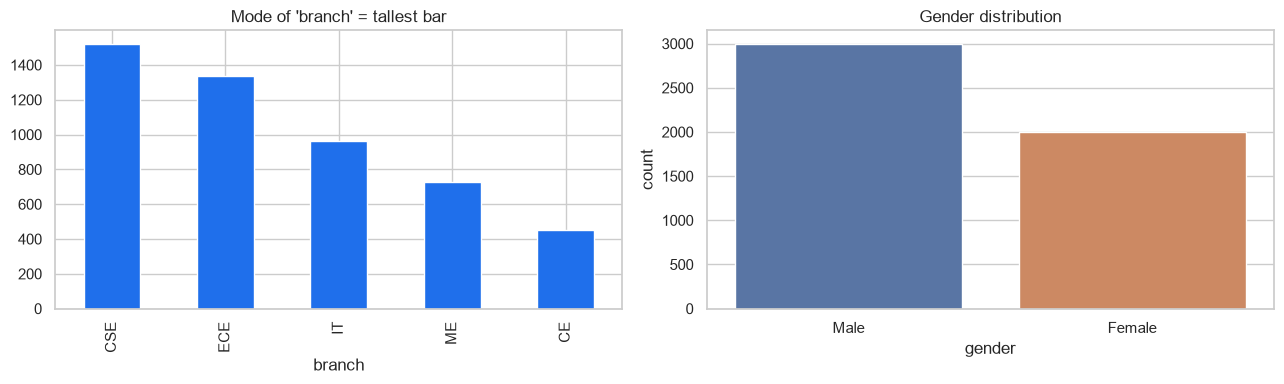

In [ ]:
# Mode is the ONLY choice for categorical data
for c in ["branch", "gender", "stress_level", "family_income_level"]:
    if c in df.columns:
        print(f"{c:22s} -> mode = {df[c].mode()[0]}")

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
sns.countplot(data=df, x="branch", order=df["branch"].value_counts().index,
              color=BLUE, ax=ax[0])
ax[0].set_title("Mode of 'branch' = tallest bar")
sns.countplot(data=df, x="gender", hue="gender", legend=False, ax=ax[1])
ax[1].set_title("Gender distribution")
plt.tight_layout(); plt.show()


### 1.1 💥 The outlier demo — why median beats mean on skewed data

In [ ]:
salaries = np.array([30, 35, 40, 45, 50])            # in thousands / month
with_ceo = np.append(salaries, 10_000)               # one CEO joins the company

report = pd.DataFrame({
    "Mean":   [salaries.mean(), with_ceo.mean()],
    "Median": [np.median(salaries), np.median(with_ceo)],
}, index=["Without CEO", "With CEO"])
display(report)

print("\nThe mean jumped by", f"{with_ceo.mean() - salaries.mean():,.0f}k",
      "but the median moved only", f"{np.median(with_ceo) - np.median(salaries):,.1f}k")
print("=> For skewed data ALWAYS report the median.")

,Mean,Median
Without CEO,40.000,40.000
With CEO,"1,700.000",42.500



The mean jumped by 1,660k but the median moved only 2.5k
=> For skewed data ALWAYS report the median.


In [10]:
# Same effect on real data: inject 20 fake 'genius' records
fake = df[col].tolist() + [10.0] * 20
print(f"original  -> mean {np.mean(df[col]):.4f} | median {np.median(df[col]):.4f}")
print(f"+outliers -> mean {np.mean(fake):.4f} | median {np.median(fake):.4f}")

original  -> mean 8.2838 | median 8.3200
+outliers -> mean 8.2906 | median 8.3200


### 🧪 YOUR TURN
Compute mean, median and mode of `study_hours_per_day`. Which one best represents a *typical* student? Why?

In [11]:
# your code here

---
## 2. Measures of Dispersion

$$s^2=\frac{\sum (x_i-\bar{x})^2}{n-1}\qquad s=\sqrt{s^2}\qquad IQR=Q_3-Q_1$$

Class A: mean=7.00  std=0.00  range=0.00
Class B: mean=7.00  std=3.00  range=6.00


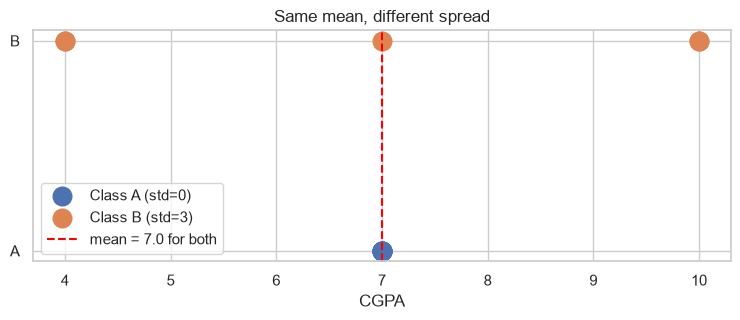

In [ ]:
# Two classes, SAME mean, totally different reality
class_A = np.array([7.0, 7.0, 7.0, 7.0, 7.0])
class_B = np.array([4.0, 4.0, 7.0, 10.0, 10.0])

for name, arr in [("Class A", class_A), ("Class B", class_B)]:
    print(f"{name}: mean={arr.mean():.2f}  std={arr.std(ddof=1):.2f}  range={arr.max()-arr.min():.2f}")

classes = pd.DataFrame({
    "cgpa":  np.concatenate([class_A, class_B]),
    "class": ["Class A (std 0.00)"] * 5 + ["Class B (std 3.00)"] * 5,
})

plt.figure(figsize=(9, 3))
sns.stripplot(data=classes, x="cgpa", y="class", hue="class", s=14, jitter=False, legend=False)
plt.axvline(7.0, color=RED, ls="--", label="mean = 7.0 for both")
plt.legend(); plt.title("Same mean, different spread"); plt.show()


In [13]:
# Hand-worked example from the notes: 2,4,4,4,5,5,7,9
d = np.array([2, 4, 4, 4, 5, 5, 7, 9])
mean_d = d.mean()
dev = d - mean_d
sq = dev ** 2

steps = pd.DataFrame({"x": d, "x - mean": dev, "(x - mean)^2": sq})
display(steps)

print(f"mean                    = {mean_d}")
print(f"sum of deviations       = {dev.sum():.1f}   <-- ALWAYS 0, that is why we square!")
print(f"sum of squared devs     = {sq.sum()}")
print(f"population variance /n  = {sq.sum()/len(d):.4f}  -> sigma = {np.sqrt(sq.sum()/len(d)):.4f}")
print(f"sample variance /(n-1)  = {sq.sum()/(len(d)-1):.4f}  -> s     = {np.sqrt(sq.sum()/(len(d)-1)):.4f}")

,x,x - mean,(x - mean)^2
0,2,-3.000,9.000
1,4,-1.000,1.000
2,4,-1.000,1.000
3,4,-1.000,1.000
4,5,0.000,0.000
5,5,0.000,0.000
6,7,2.000,4.000
7,9,4.000,16.000


mean                    = 5.0
sum of deviations       = 0.0   <-- ALWAYS 0, that is why we square!
sum of squared devs     = 32.0
population variance /n  = 4.0000  -> sigma = 2.0000
sample variance /(n-1)  = 4.5714  -> s     = 2.1381


In [14]:
# ⚠️ THE CLASSIC INTERVIEW TRAP: ddof
print("numpy  var (ddof=0, population):", np.var(d))
print("numpy  var (ddof=1, sample)    :", np.var(d, ddof=1))
print("pandas var (default = ddof=1)  :", pd.Series(d).var())
print("\npandas uses n-1 by DEFAULT, numpy uses n by DEFAULT.")

numpy  var (ddof=0, population): 4.0
numpy  var (ddof=1, sample)    : 4.571428571428571
pandas var (default = ddof=1)  : 4.571428571428571

pandas uses n-1 by DEFAULT, numpy uses n by DEFAULT.


In [15]:
# Full dispersion report for the dataset
def dispersion_report(frame):
    q1 = frame.quantile(0.25)
    q3 = frame.quantile(0.75)
    out = pd.DataFrame({
        "min": frame.min(),
        "max": frame.max(),
        "range": frame.max() - frame.min(),
        "variance": frame.var(),
        "std_dev": frame.std(),
        "IQR": q3 - q1,
        "CV_%": (frame.std() / frame.mean() * 100),
    })
    return out.sort_values("CV_%", ascending=False)

dispersion_report(num_df)

,min,max,range,variance,std_dev,IQR,CV_%
backlogs,0.000,5.000,5.000,0.375,0.613,1.000,178.273
certifications_count,0.000,9.000,9.000,3.175,1.782,2.000,62.825
Student_ID,1.000,"5,000.000","4,999.000","2,083,750.000","1,443.520","2,499.500",57.729
internships_completed,0.000,4.000,4.000,1.308,1.144,2.000,53.630
study_hours_per_day,0.000,10.000,10.000,3.872,1.968,2.700,48.693
stress_level,1.000,10.000,9.000,8.129,2.851,5.000,47.361
communication_skill_rating,1.000,5.000,4.000,1.995,1.412,2.000,46.683
hackathons_participated,0.000,6.000,6.000,2.570,1.603,2.000,43.282
projects_completed,0.000,8.000,8.000,4.218,2.054,3.000,37.143
coding_skill_rating,1.000,5.000,4.000,1.634,1.278,2.000,34.288


**Coefficient of Variation (CV = s/x̄ × 100)** lets you compare spread across different units.
The column at the top is the *least consistent* feature across students.

cgpa: lower fence=5.495, upper fence=11.135, outliers found=23


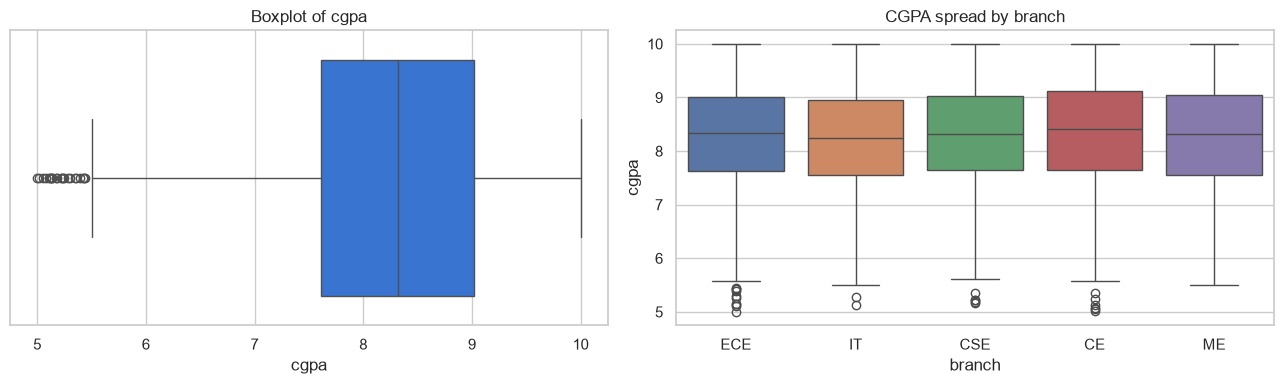

In [16]:
# IQR outlier rule + boxplot
def iqr_outliers(series):
    q1, q3 = series.quantile([0.25, 0.75])
    iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    mask = (series < lo) | (series > hi)
    return lo, hi, series[mask]

lo, hi, outs = iqr_outliers(df[col])
print(f"{col}: lower fence={lo:.3f}, upper fence={hi:.3f}, outliers found={len(outs)}")

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
sns.boxplot(x=df[col], ax=ax[0], color="#1f6feb"); ax[0].set_title(f"Boxplot of {col}")
sns.boxplot(data=df, x="branch", y=col, ax=ax[1], hue="branch", legend=False)
ax[1].set_title("CGPA spread by branch"); plt.tight_layout(); plt.show()

Q1     = 7.61
median = 8.32
Q3     = 9.02
IQR    = Q3 - Q1 = 1.41   <- the middle 50% of students
fences = 5.50  to  11.13  <- anything outside is an outlier


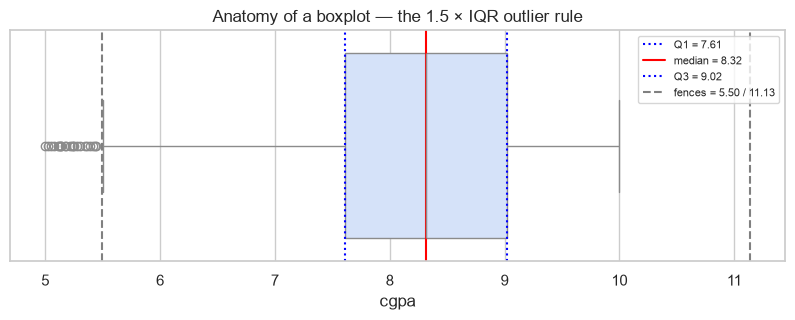

In [68]:
# Anatomy of a boxplot - the five numbers it draws
q1 = df[col].quantile(0.25)
med = df[col].quantile(0.50)
q3 = df[col].quantile(0.75)
iqr = q3 - q1
lo = q1 - 1.5 * iqr
hi = q3 + 1.5 * iqr

print(f"Q1     = {q1:.2f}")
print(f"median = {med:.2f}")
print(f"Q3     = {q3:.2f}")
print(f"IQR    = Q3 - Q1 = {iqr:.2f}   <- the middle 50% of students")
print(f"fences = {lo:.2f}  to  {hi:.2f}  <- anything outside is an outlier")

plt.figure(figsize=(10, 3))
sns.boxplot(data=df, x=col, color="#cfe0ff")
plt.axvline(q1, color="Blue", ls=":", label=f"Q1 = {q1:.2f}")
plt.axvline(med, color="Red", label=f"median = {med:.2f}")
plt.axvline(q3, color="Blue", ls=":", label=f"Q3 = {q3:.2f}")
plt.axvline(lo, color="gray", ls="--", label=f"fences = {lo:.2f} / {hi:.2f}")
plt.axvline(hi, color="gray", ls="--")
plt.title("Anatomy of a boxplot — the 1.5 × IQR outlier rule")
plt.legend(fontsize=8); plt.show()


### 🧪 YOUR TURN
Which numeric column has the **most outliers** by the 1.5×IQR rule? Loop over `num_df.columns`.

In [17]:
# your code here

---
## 3. Distributions & Skewness

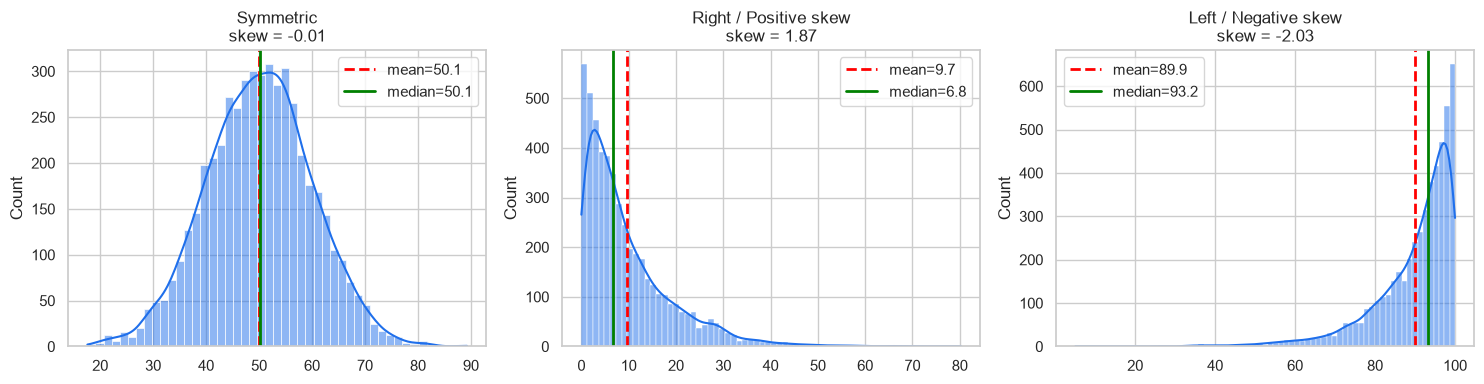

Remember: THE TAIL PULLS THE MEAN.


In [18]:
# The three shapes, side by side
sym   = np.random.normal(50, 10, 5000)
right = np.random.exponential(10, 5000)          # like salary
left  = 100 - np.random.exponential(10, 5000)    # like an easy exam

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, data, title in zip(axes, [sym, right, left],
                           ["Symmetric", "Right / Positive skew", "Left / Negative skew"]):
    sns.histplot(data, kde=True, ax=ax, color="#1f6feb")
    ax.axvline(np.mean(data),   color="red",   ls="--", lw=2, label=f"mean={np.mean(data):.1f}")
    ax.axvline(np.median(data), color="green", ls="-",  lw=2, label=f"median={np.median(data):.1f}")
    ax.set_title(f"{title}\nskew = {stats.skew(data):.2f}"); ax.legend()
plt.tight_layout(); plt.show()

print("Remember: THE TAIL PULLS THE MEAN.")

In [19]:
# Skewness & kurtosis of the real columns
shape = pd.DataFrame({"skewness": num_df.skew(), "kurtosis": num_df.kurtosis()})
shape["verdict"] = pd.cut(shape["skewness"], [-np.inf, -0.5, 0.5, np.inf],
                          labels=["left skewed", "fairly symmetric", "right skewed"])
shape.sort_values("skewness")

,skewness,kurtosis,verdict
coding_skill_rating,-0.565,-0.921,left skewed
projects_completed,-0.533,-0.689,left skewed
hackathons_participated,-0.374,-0.655,fairly symmetric
aptitude_skill_rating,-0.368,-0.361,fairly symmetric
cgpa,-0.288,-0.322,fairly symmetric
sleep_hours,-0.172,-0.492,fairly symmetric
tenth_percentage,-0.135,-0.445,fairly symmetric
stress_level,-0.134,-1.172,fairly symmetric
twelfth_percentage,-0.091,-0.353,fairly symmetric
internships_completed,-0.088,-0.762,fairly symmetric


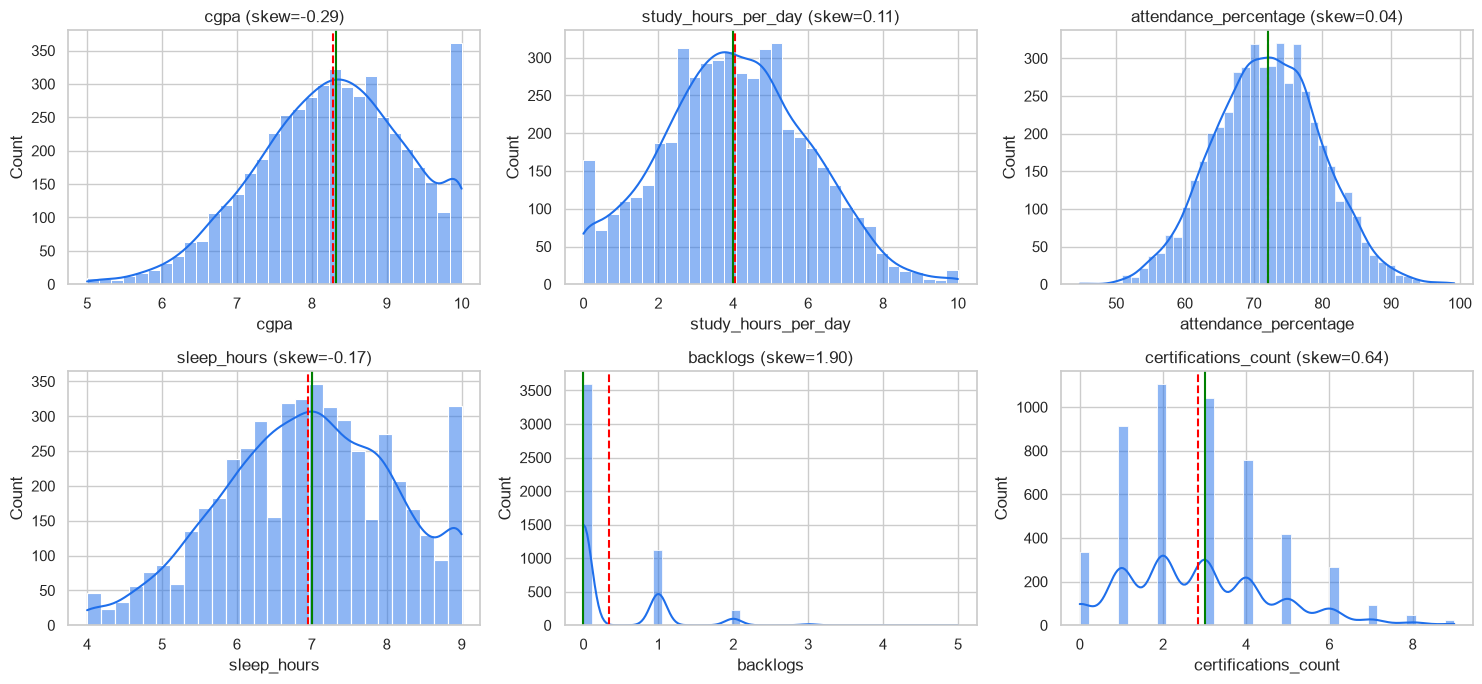

In [20]:
# Histograms of a few interesting columns
cols = [c for c in ["cgpa", "study_hours_per_day", "attendance_percentage",
                    "sleep_hours", "backlogs", "certifications_count"] if c in df.columns]

fig, axes = plt.subplots(2, 3, figsize=(15, 7))
for ax, c in zip(axes.ravel(), cols):
    sns.histplot(df[c], kde=True, ax=ax, color="#1f6feb")
    ax.axvline(df[c].mean(), color="red", ls="--")
    ax.axvline(df[c].median(), color="green")
    ax.set_title(f"{c} (skew={df[c].skew():.2f})")
plt.tight_layout(); plt.show()

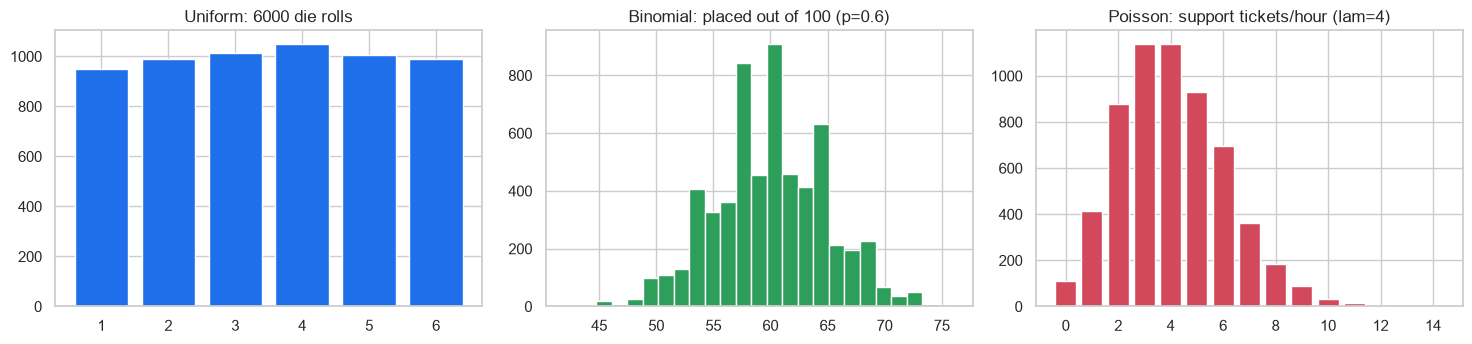

In [ ]:
# Discrete distributions you should recognise
fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))

sns.histplot(x=np.random.randint(1, 7, 6000), bins=np.arange(0.5, 7.5),
             shrink=.8, color=BLUE, ax=ax[0])
ax[0].set_title("Uniform: 6000 die rolls")

sns.histplot(x=np.random.binomial(n=100, p=0.6, size=6000), bins=25, color=GREEN, ax=ax[1])
ax[1].set_title("Binomial: placed out of 100 (p=0.6)")

sns.histplot(x=np.random.poisson(lam=4, size=6000), bins=np.arange(-0.5, 15),
             shrink=.8, color=RED, ax=ax[2])
ax[2].set_title("Poisson: support tickets/hour (lam=4)")

for a in ax:
    a.set_ylabel("")
plt.tight_layout(); plt.show()


---
## 4. Probability Basics (by simulation)

$$P(A)=\frac{\text{favourable}}{\text{total}},\qquad P(A\cup B)=P(A)+P(B)-P(A\cap B),\qquad P(A|B)=\frac{P(A\cap B)}{P(B)}$$

Theoretical P(even) = 3/6 = 0.5
Simulated   P(even) = 0.4997


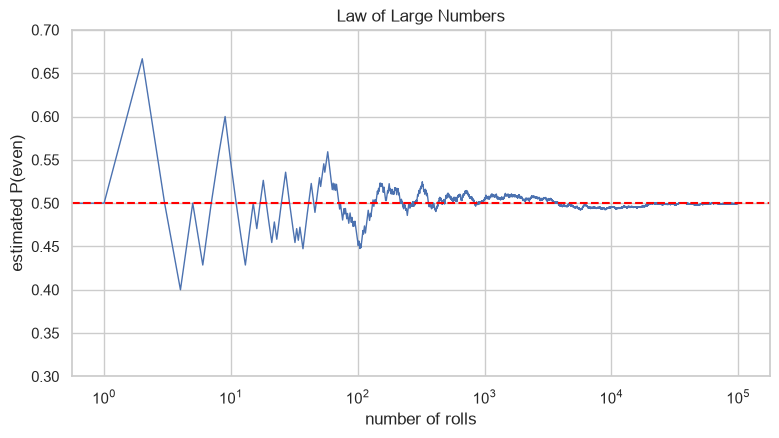

In [ ]:
# Theory vs simulation: probability of an even number on a fair die
rolls = np.random.randint(1, 7, 100_000)
print(f"Theoretical P(even) = 3/6 = 0.5")
print(f"Simulated   P(even) = {(rolls % 2 == 0).mean():.4f}")

# Law of large numbers: estimate stabilises as n grows
running = np.cumsum(rolls % 2 == 0) / np.arange(1, len(rolls) + 1)
lln = pd.DataFrame({"rolls": np.arange(1, len(rolls) + 1), "estimate": running})

sns.lineplot(data=lln[::20], x="rolls", y="estimate", color=BLUE, lw=1)
plt.axhline(0.5, color=RED, ls="--", label="true P = 0.5")
plt.xscale("log"); plt.ylim(0.3, 0.7)
plt.title("Law of Large Numbers"); plt.legend(); plt.show()


In [23]:
# Real probabilities straight from the data
N = len(df)
p_cse   = (df["branch"] == "CSE").mean()
p_high  = (df["cgpa"] > 8).mean()
p_both  = ((df["branch"] == "CSE") & (df["cgpa"] > 8)).mean()

print(f"P(CSE)            = {p_cse:.4f}")
print(f"P(CGPA > 8)       = {p_high:.4f}")
print(f"P(CSE and >8)     = {p_both:.4f}")
print(f"P(CSE or  >8)     = {p_cse + p_high - p_both:.4f}   (addition rule)")
print(f"P(>8 | CSE)       = {p_both / p_cse:.4f}            (conditional)")
print(f"P(CSE) * P(>8)    = {p_cse * p_high:.4f}            (if they were independent)")
print("\nIf the last two lines differ from P(CSE and >8), the events are NOT independent.")

P(CSE)            = 0.3044
P(CGPA > 8)       = 0.6202
P(CSE and >8)     = 0.1918
P(CSE or  >8)     = 0.7328   (addition rule)
P(>8 | CSE)       = 0.6301            (conditional)
P(CSE) * P(>8)    = 0.1888            (if they were independent)

If the last two lines differ from P(CSE and >8), the events are NOT independent.


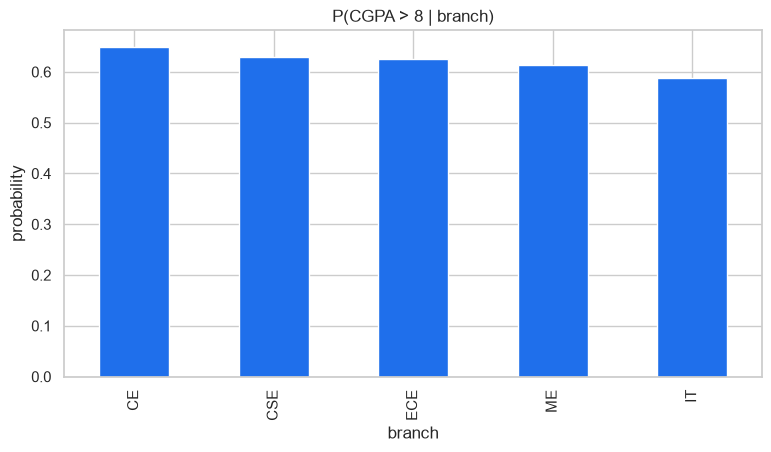

,P(cgpa>8 | branch)
branch,
CE,0.650
CSE,0.630
ECE,0.625
ME,0.614
IT,0.589


In [ ]:
# Conditional probability table: P(CGPA > 8 | branch)
cond = (df.groupby("branch")["cgpa"]
          .apply(lambda s: (s > 8).mean())
          .sort_values(ascending=False)
          .reset_index(name="P(cgpa>8 | branch)"))

sns.barplot(data=cond, x="branch", y="P(cgpa>8 | branch)", color=BLUE)
plt.title("P(CGPA > 8 | branch)"); plt.ylabel("probability"); plt.show()
cond


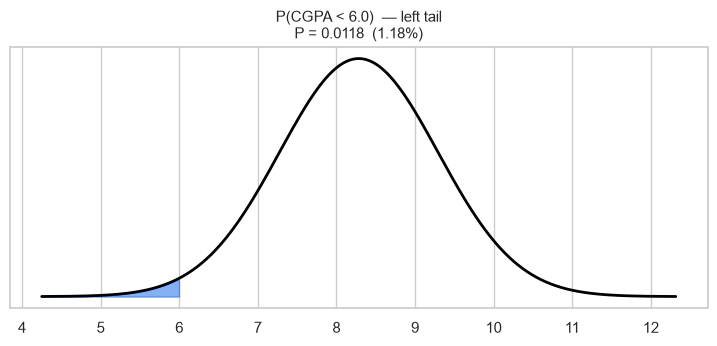

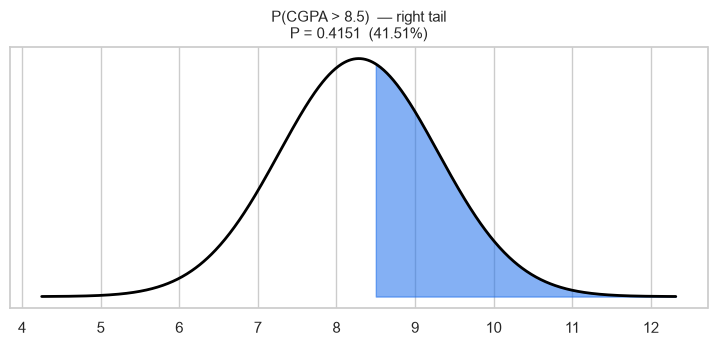

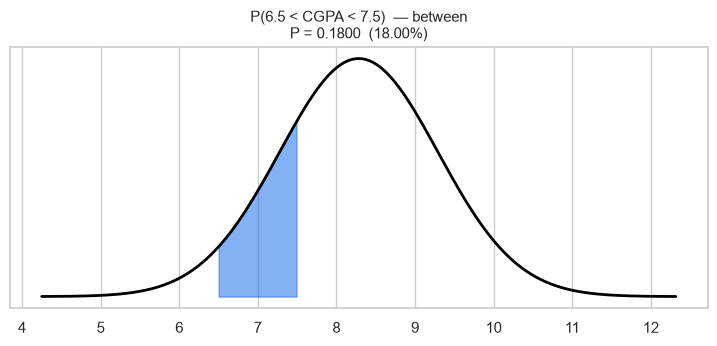

In [ ]:
# Continuous probability = AREA under the curve. Here is that idea, drawn.
def shade_normal(mu, sigma, a=None, b=None, title=""):
    x = np.linspace(mu - 4*sigma, mu + 4*sigma, 800)
    curve = pd.DataFrame({"x": x, "density": stats.norm.pdf(x, mu, sigma)})
    lo_ = a if a is not None else -np.inf
    hi_ = b if b is not None else np.inf
    prob = stats.norm.cdf(hi_, mu, sigma) - stats.norm.cdf(lo_, mu, sigma)

    plt.figure(figsize=(9, 3.4))
    sns.lineplot(data=curve, x="x", y="density", color="black", lw=2)
    band = curve[curve["x"].between(lo_, hi_)]
    sns.lineplot(data=band, x="x", y="density", color=BLUE, lw=0)
    plt.fill_between(band["x"], band["density"], color=BLUE, alpha=.55)   # shading needs plt
    plt.title(f"{title}\nP = {prob:.4f}  ({prob*100:.2f}%)", fontsize=11)
    plt.ylabel(""); plt.yticks([]); plt.show()
    return prob


mu_, sd_ = df[col].mean(), df[col].std()
shade_normal(mu_, sd_, b=6.0,        title="P(CGPA < 6.0)  — left tail")
shade_normal(mu_, sd_, a=8.5,        title="P(CGPA > 8.5)  — right tail")
shade_normal(mu_, sd_, a=6.5, b=7.5, title="P(6.5 < CGPA < 7.5)  — between");


---
## 5. Normal & Standard Normal Distribution, Z-scores

$$z=\frac{x-\mu}{\sigma}\qquad\text{Standard Normal: } Z\sim N(0,1)$$

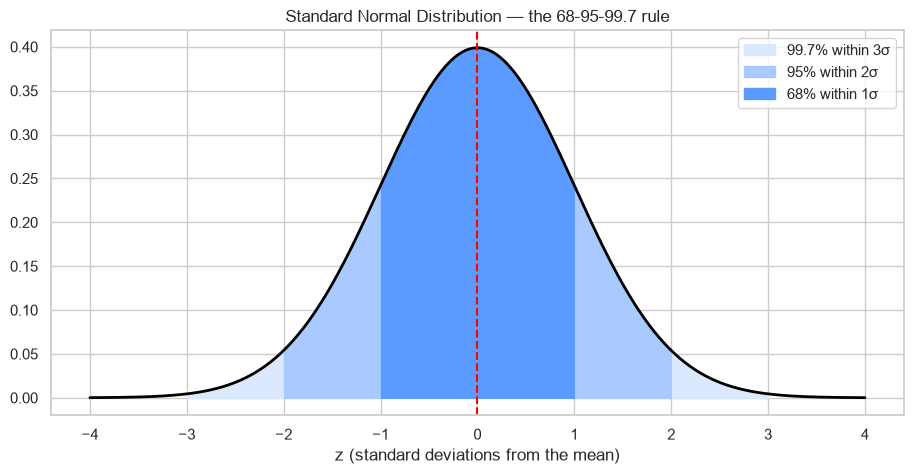

within 1 sigma -> 68.27%
within 2 sigma -> 95.45%
within 3 sigma -> 99.73%


In [ ]:
# The Empirical Rule, drawn
xs = np.linspace(-4, 4, 600)
curve = pd.DataFrame({"z": xs, "density": stats.norm.pdf(xs)})

plt.figure(figsize=(11, 5))
sns.lineplot(data=curve, x="z", y="density", color="black", lw=2)
for k, c, lbl in [(3, "#dbe9ff", "99.7% within 3σ"),
                  (2, "#a8caff", "95% within 2σ"),
                  (1, "#5b9bff", "68% within 1σ")]:
    band = curve[curve["z"].between(-k, k)]
    plt.fill_between(band["z"], band["density"], color=c, label=lbl)
plt.axvline(0, color=RED, ls="--")
plt.title("Standard Normal Distribution — the 68-95-99.7 rule")
plt.xlabel("z (standard deviations from the mean)")
plt.ylabel(""); plt.yticks([]); plt.legend(); plt.show()

for k in (1, 2, 3):
    area = stats.norm.cdf(k) - stats.norm.cdf(-k)
    print(f"within {k} sigma -> {area*100:.2f}%")


actual % within 1 sigma = 65.84%   (theory: 68.27%)
actual % within 2 sigma = 97.24%   (theory: 95.45%)
actual % within 3 sigma = 99.70%   (theory: 99.73%)


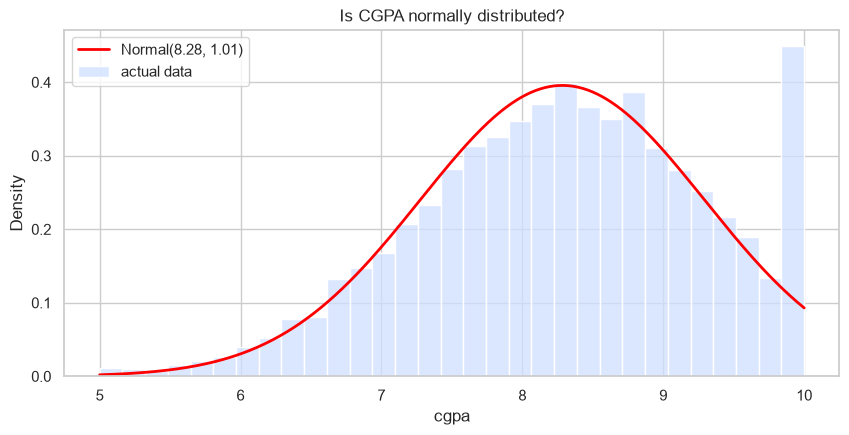

In [ ]:
# Does the real CGPA follow the empirical rule?
m, s_ = df[col].mean(), df[col].std()
for k in (1, 2, 3):
    pct = df[col].between(m - k*s_, m + k*s_).mean() * 100
    print(f"actual % within {k} sigma = {pct:5.2f}%   (theory: {[68.27,95.45,99.73][k-1]}%)")

xs = np.linspace(df[col].min(), df[col].max(), 300)
fitted = pd.DataFrame({col: xs, "density": stats.norm.pdf(xs, m, s_)})

plt.figure(figsize=(10, 4.5))
sns.histplot(data=df, x=col, stat="density", color="#cfe0ff", label="actual data")
sns.lineplot(data=fitted, x=col, y="density", color=RED, lw=2,
             label=f"Normal({m:.2f}, {s_:.2f})")
plt.title("Is CGPA normally distributed?"); plt.legend(); plt.show()


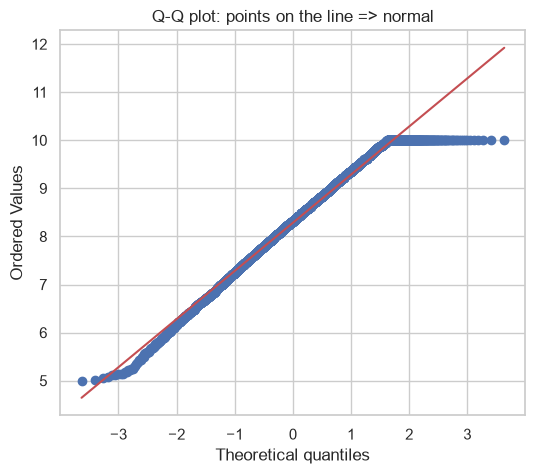

Shapiro-Wilk: W=0.9847, p=0.0000
p <= 0.05 -> data deviates from normal


In [27]:
# Normality checks: Q-Q plot + Shapiro-Wilk
fig = plt.figure(figsize=(6, 5))
stats.probplot(df[col].dropna(), dist="norm", plot=plt)
plt.title("Q-Q plot: points on the line => normal"); plt.show()

sample_for_test = df[col].dropna().sample(min(500, len(df)), random_state=0)
stat, p = stats.shapiro(sample_for_test)
print(f"Shapiro-Wilk: W={stat:.4f}, p={p:.4f}")
print("p > 0.05 -> cannot reject normality" if p > 0.05 else "p <= 0.05 -> data deviates from normal")

In [28]:
# Z-SCORES: convert raw values into 'how many std devs from the mean'
df["cgpa_z"] = stats.zscore(df[col])

print(f"mean of z = {df['cgpa_z'].mean():.6f}  (should be ~0)")
print(f"std  of z = {df['cgpa_z'].std(ddof=0):.6f}  (should be ~1)\n")

df[[ "Student_ID", col, "cgpa_z"]].sort_values("cgpa_z", ascending=False).head(5)

mean of z = 0.000000  (should be ~0)
std  of z = 1.000000  (should be ~1)



,Student_ID,cgpa,cgpa_z
4995,4996,10.000,1.702
4970,4971,10.000,1.702
4990,4991,10.000,1.702
3947,3948,10.000,1.702
800,801,10.000,1.702


In [29]:
# Interpreting a single student
def explain_z(value, mu, sigma, label="CGPA"):
    z = (value - mu) / sigma
    pct = stats.norm.cdf(z) * 100
    print(f"{label} = {value}")
    print(f"  z-score    = {z:+.3f}")
    print(f"  percentile = {pct:.2f}%  (better than {pct:.1f}% of students)")
    print(f"  P(above)   = {100-pct:.2f}%\n")

explain_z(8.6, m, s_)
explain_z(9.5, m, s_)
explain_z(5.5, m, s_)

CGPA = 8.6
  z-score    = +0.314
  percentile = 62.31%  (better than 62.3% of students)
  P(above)   = 37.69%

CGPA = 9.5
  z-score    = +1.206
  percentile = 88.61%  (better than 88.6% of students)
  P(above)   = 11.39%

CGPA = 5.5
  z-score    = -2.761
  percentile = 0.29%  (better than 0.3% of students)
  P(above)   = 99.71%



,feature,raw value,z-score,percentile
0,cgpa,8.740,0.452,67.451
1,attendance_percentage,71.100,-0.122,45.146
2,coding_skill_rating,4.000,0.212,58.406
3,study_hours_per_day,3.800,-0.123,45.124


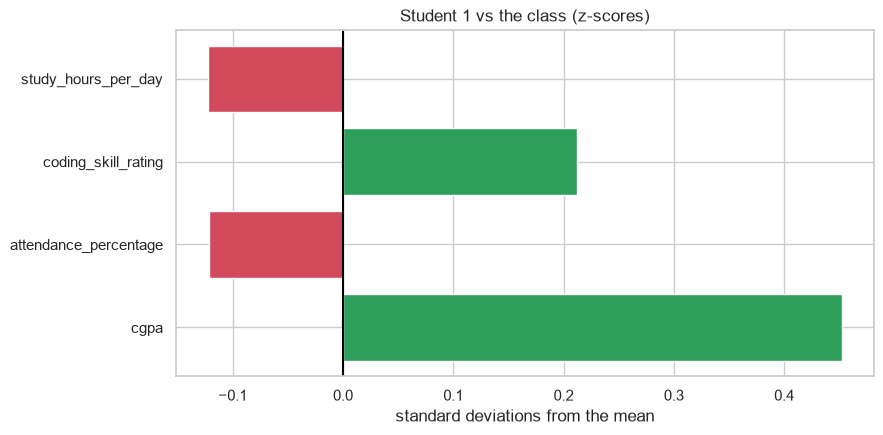

In [ ]:
# Comparing apples to oranges - the killer use case of z-scores
student = df.iloc[0]
compare = []
for c in ["cgpa", "attendance_percentage", "coding_skill_rating", "study_hours_per_day"]:
    if c in df.columns:
        z = (student[c] - df[c].mean()) / df[c].std()
        compare.append({"feature": c, "raw value": student[c],
                        "z-score": z, "percentile": stats.norm.cdf(z) * 100})
cmp_df = pd.DataFrame(compare)
display(cmp_df)

cmp_df["side"] = np.where(cmp_df["z-score"] > 0, "above average", "below average")
sns.barplot(data=cmp_df, x="z-score", y="feature", hue="side",
            palette={"above average": GREEN, "below average": RED}, dodge=False)
plt.axvline(0, color="black")
plt.title(f"Student {student['Student_ID']} vs the class (z-scores)")
plt.xlabel("standard deviations from the mean"); plt.show()


In [31]:
# 3-sigma outlier detection using z-scores
extreme = df[np.abs(df["cgpa_z"]) > 3]
print(f"Students beyond 3 sigma: {len(extreme)} out of {len(df)} ({len(extreme)/len(df)*100:.2f}%)")
extreme[["Student_ID", "branch", col, "cgpa_z"]].head()

Students beyond 3 sigma: 15 out of 5000 (0.30%)


,Student_ID,branch,cgpa,cgpa_z
209,210,CSE,5.230,-3.029
218,219,CSE,5.170,-3.088
1544,1545,ECE,5.110,-3.148
2457,2458,ECE,5.140,-3.118
2703,2704,ECE,5.250,-3.009


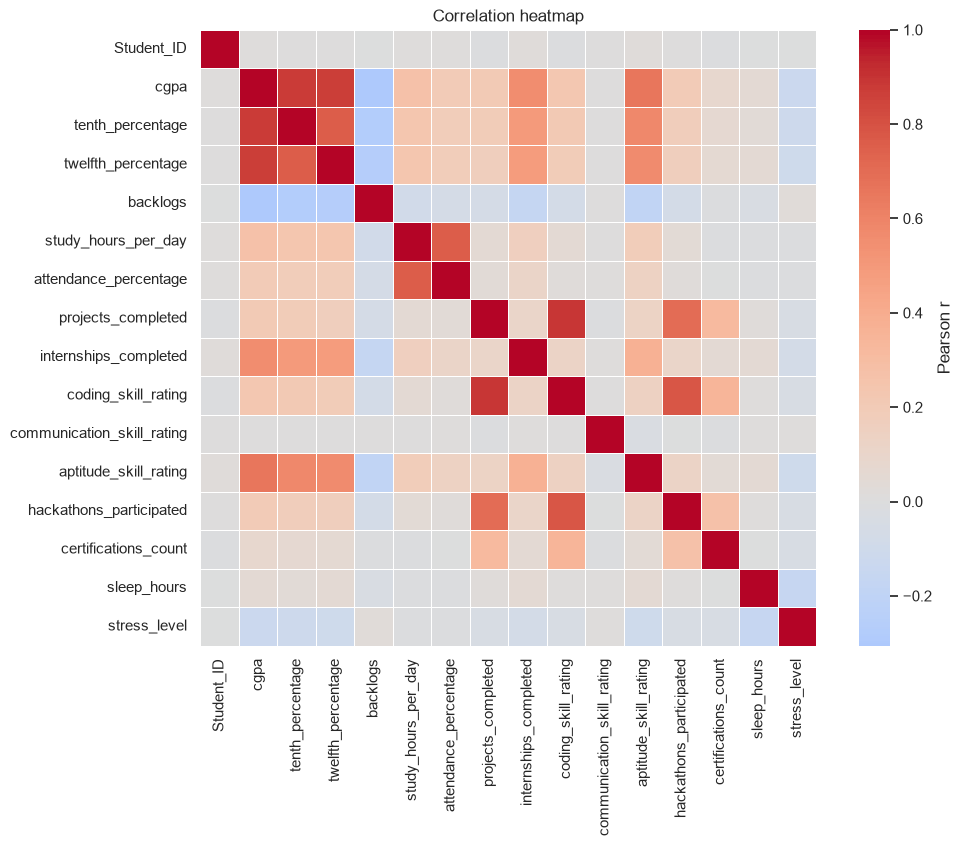

Strongest correlations with cgpa
tenth_percentage        0.880
twelfth_percentage      0.872
aptitude_skill_rating   0.662


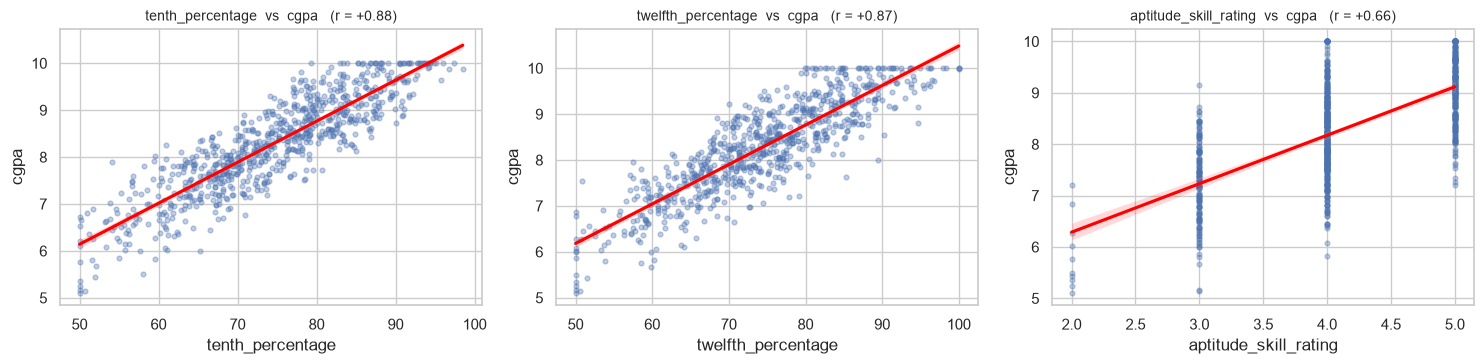

In [56]:
# Which features move together? (correlation != causation, but it's where every project starts)
corr = num_df.corr(numeric_only=True)

plt.figure(figsize=(11, 8))
sns.heatmap(corr, cmap="coolwarm", center=0, annot=False, square=True,
            linewidths=.4, cbar_kws={"label": "Pearson r"})
plt.title("Correlation heatmap"); plt.show()

top = (corr[col].drop(col).sort_values(key=abs, ascending=False).head(3))
print("Strongest correlations with", col)
print(top.to_string())

fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
for ax, feat in zip(axes, top.index):
    sns.regplot(data=df.sample(800, random_state=0), x=feat, y=col, ax=ax,
                scatter_kws=dict(s=12, alpha=.35), line_kws=dict(color="red"))
    ax.set_title(f"{feat}  vs  {col}   (r = {corr.loc[feat, col]:+.2f})", fontsize=10)
plt.tight_layout(); plt.show()


### 🧪 YOUR TURN
Assume `attendance_percentage` is normal. What percentage of students attend **more than 90%** of classes?
Compute it with `stats.norm.cdf` and check against the actual data.

In [32]:
# your code here

---
## 6. Sampling Techniques & the Central Limit Theorem

We treat the full CSV as our **population** and draw samples from it.

In [8]:
population = df.copy()
POP_MEAN = population[col].mean()
POP_STD  = population[col].std(ddof=0)
print(f"POPULATION: N={len(population)}, mu={POP_MEAN:.4f}, sigma={POP_STD:.4f}")

POPULATION: N=5000, mu=8.2838, sigma=1.0083


In [9]:
# 1) SIMPLE RANDOM SAMPLING - pure lottery
srs = population.sample(n=200, random_state=42)
sample_STD  = srs[col].std(ddof=1)
print(f"Simple random  : n={len(srs)}, mean={srs[col].mean():.4f}, error={srs[col].mean()-POP_MEAN:+.4f}, sigma={sample_STD:.4f}")

Simple random  : n=200, mean=8.3119, error=+0.0282, sigma=1.0821


In [35]:
# 2) STRATIFIED SAMPLING - keep each branch's proportion intact
strat = population.groupby("branch", group_keys=False).sample(frac=0.05, random_state=42)
print(f"Stratified     : n={len(strat)}, mean={strat[col].mean():.4f}, error={strat[col].mean()-POP_MEAN:+.4f}\n")

comparison = pd.DataFrame({
    "population %": population["branch"].value_counts(normalize=True) * 100,
    "stratified  %": strat["branch"].value_counts(normalize=True) * 100,
    "simple rand %": srs["branch"].value_counts(normalize=True) * 100,
}).round(2)
comparison

Stratified     : n=250, mean=8.2319, error=-0.0519



,population %,stratified %,simple rand %
branch,,,
CE,9.080,9.200,7.500
CSE,30.440,30.400,31.000
ECE,26.720,26.800,33.500
IT,19.260,19.200,15.000
ME,14.500,14.400,13.000


👆 Notice how the **stratified** column matches the population proportions almost exactly, while simple random sampling drifts. That is the whole point of stratification.

In [36]:
# 3) SYSTEMATIC SAMPLING - every k-th record
n_want = 200
k = len(population) // n_want
start = np.random.randint(0, k)
syst = population.iloc[start::k]
print(f"Systematic (k={k}, start={start}): n={len(syst)}, mean={syst[col].mean():.4f}, "
      f"error={syst[col].mean()-POP_MEAN:+.4f}")

# 4) CLUSTER SAMPLING - pick whole groups (here: branches act as clusters)
clusters = population["branch"].unique()
chosen = np.random.choice(clusters, size=2, replace=False)
clust = population[population["branch"].isin(chosen)]
print(f"Cluster (branches={list(chosen)}): n={len(clust)}, mean={clust[col].mean():.4f}, "
      f"error={clust[col].mean()-POP_MEAN:+.4f}")

Systematic (k=25, start=23): n=200, mean=8.2241, error=-0.0597
Cluster (branches=['ME', 'CE']): n=1179, mean=8.2820, error=-0.0018


In [37]:
# 5) BIASED SAMPLE - what happens when you sample badly (convenience sampling)
biased = population[population[col] > 8].sample(200, replace=True, random_state=1)
print(f"Biased ('only toppers replied to my survey'): mean={biased[col].mean():.4f}, "
      f"error={biased[col].mean()-POP_MEAN:+.4f}")
print("\n>>> No amount of clever math can fix a biased sample. <<<")

Biased ('only toppers replied to my survey'): mean=9.0096, error=+0.7258

>>> No amount of clever math can fix a biased sample. <<<


,n,theoretical SE,observed SE
0,10,0.319,0.302
1,30,0.184,0.185
2,100,0.101,0.093
3,400,0.050,0.053
4,1600,0.025,0.026


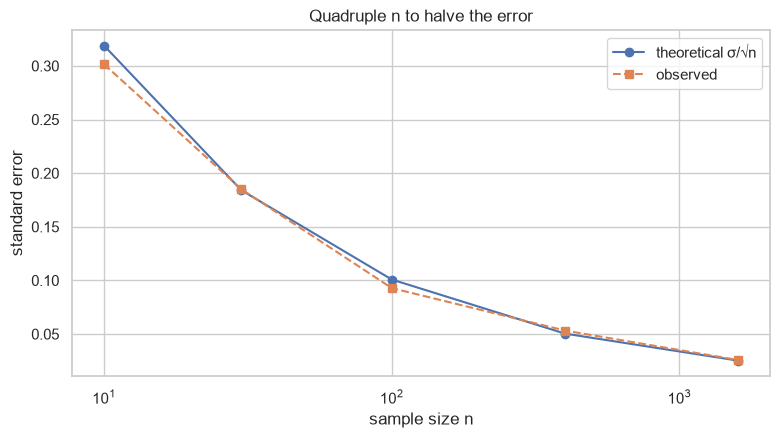

In [ ]:
# STANDARD ERROR: SE = sigma / sqrt(n)  -- the sqrt(n) law
rows = []
for n_ in [10, 30, 100, 400, 1600]:
    means = [population[col].sample(n_, replace=True).mean() for _ in range(400)]
    rows.append({"n": n_, "theoretical SE": POP_STD/np.sqrt(n_), "observed SE": np.std(means, ddof=1)})
se_df = pd.DataFrame(rows)
display(se_df)

se_long = se_df.melt(id_vars="n", var_name="source", value_name="standard error")
sns.lineplot(data=se_long, x="n", y="standard error", hue="source", style="source",
             markers=True, dashes=[(1, 0), (4, 2)], lw=2, markersize=9)
plt.xscale("log"); plt.xlabel("sample size n")
plt.title("Quadruple n to halve the error"); plt.show()


### 6.1 👑 The Central Limit Theorem in action
Start from a **horribly skewed** population and watch the distribution of *sample means* turn into a bell curve.

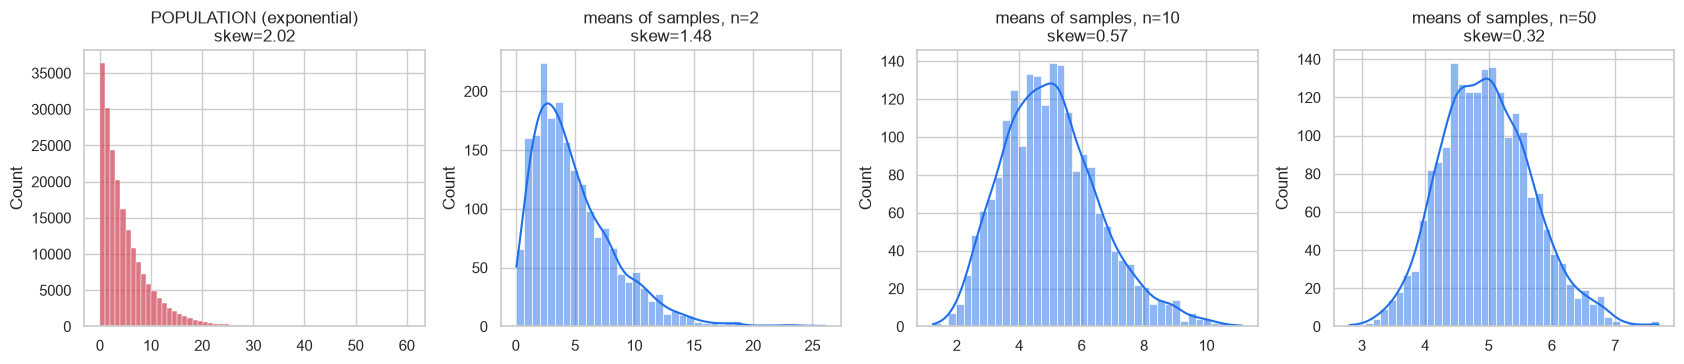

As n grows the sampling distribution of the MEAN becomes normal,
no matter how ugly the original population was. That is the CLT.


In [39]:
skewed_pop = np.random.exponential(scale=5, size=200_000)   # nothing like a normal curve

fig, axes = plt.subplots(1, 4, figsize=(17, 3.8))
sns.histplot(skewed_pop, bins=60, ax=axes[0], color="#d1495b")
axes[0].set_title(f"POPULATION (exponential)\nskew={stats.skew(skewed_pop):.2f}")

for ax, n_ in zip(axes[1:], [2, 10, 50]):
    means = skewed_pop[np.random.randint(0, len(skewed_pop), (2000, n_))].mean(axis=1)
    sns.histplot(means, bins=40, kde=True, ax=ax, color="#1f6feb")
    ax.set_title(f"means of samples, n={n_}\nskew={stats.skew(means):.2f}")
plt.tight_layout(); plt.show()

print("As n grows the sampling distribution of the MEAN becomes normal,")
print("no matter how ugly the original population was. That is the CLT.")

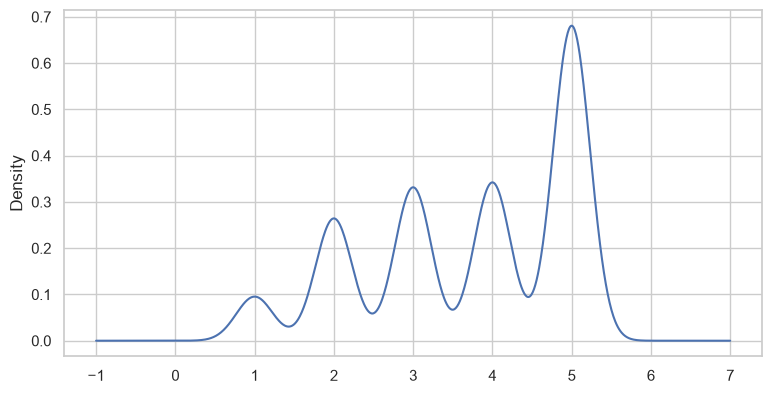

In [19]:
df['coding_skill_rating'].plot(kind='kde')

samples = []

for i in range(10):
    samples.append(df['coding_skill_rating'].sample(n=100))

<Axes: ylabel='Density'>

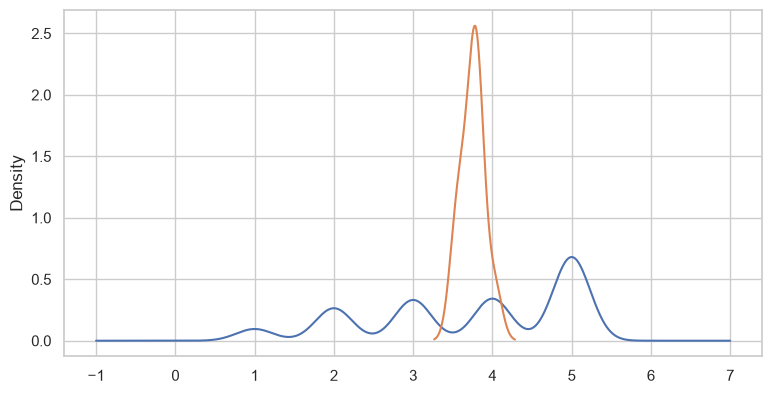

In [20]:
sample_avg = []

for sample in samples:
    sample_avg.append(sample.mean())

avg_ser = pd.Series(sample_avg)
df['coding_skill_rating'].plot(kind='kde')
avg_ser.plot(kind='kde')

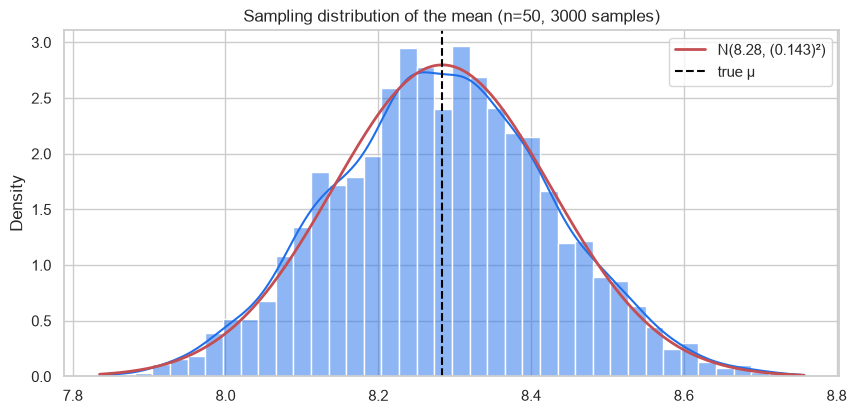

mean of sample means = 8.2831   vs  true mu = 8.2838
std  of sample means = 0.1428   vs  sigma/sqrt(n) = 0.1426


In [ ]:
# CLT on our real CGPA data + verify mean and SE predictions
n_ = 50
sample_means = np.array([population[col].sample(n_, replace=True).mean() for _ in range(3000)])

xs = np.linspace(sample_means.min(), sample_means.max(), 300)
predicted = pd.DataFrame({"mean": xs,
                          "density": stats.norm.pdf(xs, POP_MEAN, POP_STD/np.sqrt(n_))})

plt.figure(figsize=(10, 4.5))
sns.histplot(x=sample_means, bins=40, stat="density", kde=True, color=BLUE)
sns.lineplot(data=predicted, x="mean", y="density", color=RED, lw=2,
             label=f"N({POP_MEAN:.2f}, ({POP_STD/np.sqrt(n_):.3f})²)")
plt.axvline(POP_MEAN, color="black", ls="--", label="true μ")
plt.title(f"Sampling distribution of the mean (n={n_}, 3000 samples)")
plt.legend(); plt.show()

print(f"mean of sample means = {sample_means.mean():.4f}   vs  true mu = {POP_MEAN:.4f}")
print(f"std  of sample means = {sample_means.std(ddof=1):.4f}   vs  sigma/sqrt(n) = {POP_STD/np.sqrt(n_):.4f}")


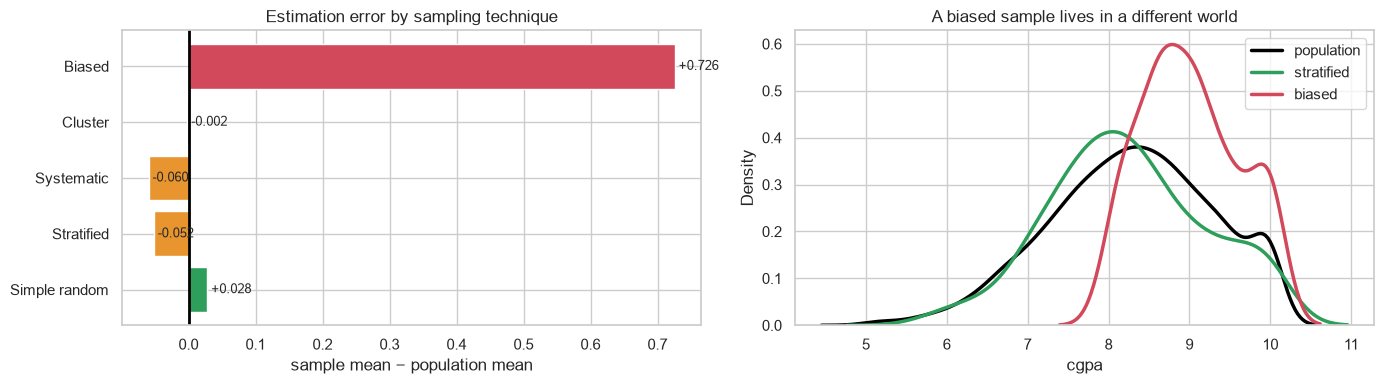

In [ ]:
# Which sampling technique got closest to the truth?
errors = pd.DataFrame({
    "technique": ["Simple random", "Stratified", "Systematic", "Cluster", "Biased"],
    "error": [srs[col].mean() - POP_MEAN, strat[col].mean() - POP_MEAN,
              syst[col].mean() - POP_MEAN, clust[col].mean() - POP_MEAN,
              biased[col].mean() - POP_MEAN],
})
errors["quality"] = pd.cut(errors["error"].abs(), [-1, .05, .3, np.inf],
                           labels=["good", "ok", "bad"])

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
sns.barplot(data=errors, x="error", y="technique", hue="quality", dodge=False,
            palette={"good": GREEN, "ok": ORANGE, "bad": RED}, ax=ax[0])
ax[0].axvline(0, color="black", lw=2)
ax[0].set_xlabel("sample mean − population mean")
ax[0].set_title("Estimation error by sampling technique")
for i, v in enumerate(errors["error"]):
    ax[0].text(v, i, f" {v:+.3f}", va="center", fontsize=9)

for name, frame, c in [("population", population, "black"), ("stratified", strat, GREEN),
                       ("biased", biased, RED)]:
    sns.kdeplot(data=frame, x=col, ax=ax[1], label=name, lw=2.5, color=c)
ax[1].set_title("A biased sample lives in a different world"); ax[1].legend()
plt.tight_layout(); plt.show()


---
## 7. Hypothesis Testing & the Z-Test

$$z=\frac{\bar{x}-\mu_0}{\sigma/\sqrt{n}}=\frac{\text{signal}}{\text{noise}}$$

**6-step recipe:** state H₀/H₁ → choose α → check assumptions → compute z → get p-value → decide.

In [41]:
def one_sample_ztest(sample, mu0, sigma=None, alpha=0.05, tail="two", label=""):
    """One-sample Z-test with a full, human-readable report."""
    sample = np.asarray(sample, dtype=float)
    n = len(sample)
    xbar = sample.mean()
    sigma = sample.std(ddof=1) if sigma is None else sigma   # OK when n >= 30 (CLT)
    se = sigma / np.sqrt(n)
    z = (xbar - mu0) / se

    if tail == "two":
        p = 2 * (1 - stats.norm.cdf(abs(z)))
        crit = stats.norm.ppf(1 - alpha / 2)
        crit_txt = f"+/-{crit:.3f}"
        reject = abs(z) > crit
    elif tail == "right":
        p = 1 - stats.norm.cdf(z)
        crit = stats.norm.ppf(1 - alpha)
        crit_txt = f"{crit:.3f}"
        reject = z > crit
    else:  # left
        p = stats.norm.cdf(z)
        crit = stats.norm.ppf(alpha)
        crit_txt = f"{crit:.3f}"
        reject = z < crit

    zc = stats.norm.ppf(1 - alpha / 2)
    ci = (xbar - zc * se, xbar + zc * se)

    print(f"=== Z-TEST {label} ===")
    print(f"H0: mu = {mu0}   |   H1: mu {'!=' if tail=='two' else ('>' if tail=='right' else '<')} {mu0}   ({tail}-tailed, alpha={alpha})")
    print(f"n = {n}   x-bar = {xbar:.4f}   sigma = {sigma:.4f}   SE = {se:.4f}")
    print(f"z statistic     = {z:.4f}")
    print(f"critical value  = {crit_txt}")
    print(f"p-value         = {p:.6f}")
    print(f"{int((1-alpha)*100)}% CI for mu  = [{ci[0]:.4f}, {ci[1]:.4f}]")
    print(f"effect size (Cohen's d) = {(xbar-mu0)/sigma:.4f}")
    print("DECISION        :", "REJECT H0  (statistically significant)" if reject
          else "FAIL TO REJECT H0  (not enough evidence)")
    print()
    return {"z": z, "p": p, "ci": ci, "reject": reject}


print("helper ready")

helper ready


### 7.1 Textbook example (matches the notes and slides)
A printer is advertised at **20 pages per minute (ppm)** with **σ = 1.5 ppm**. A reviewer tests **n = 36** printers and measures **x̄ = 19.4 ppm**. Is the printer slower than advertised?


In [62]:
mu0, sigma_known, n_, xbar = 20.0, 1.5, 36, 19.4

se = sigma_known / np.sqrt(n_)
z  = (xbar - mu0) / se
p  = stats.norm.cdf(z)          # left-tailed: is it SLOWER than claimed?

print(f"SE = {sigma_known}/sqrt({n_}) = {se:.4f}")
print(f"z  = ({xbar} - {mu0}) / {se:.2f} = {z:.4f}")
print(f"p  = cdf({z:.2f}) = {p:.6f}")
print(f"critical z (alpha=0.05, left) = {stats.norm.ppf(0.05):.4f}")
print("\nDECISION:", "REJECT H0 -> the printer IS slower than the advertised 20 ppm"
      if p < 0.05 else "FAIL TO REJECT H0")

ci = (xbar - 1.96*se, xbar + 1.96*se)
print(f"95% CI = [{ci[0]:.4f}, {ci[1]:.4f}] ppm  -> 20 ppm is outside, same conclusion")


SE = 1.5/sqrt(36) = 0.2500
z  = (19.4 - 20.0) / 0.25 = -2.4000
p  = cdf(-2.40) = 0.008198
critical z (alpha=0.05, left) = -1.6449

DECISION: REJECT H0 -> the printer IS slower than the advertised 20 ppm
95% CI = [18.9100, 19.8900] ppm  -> 20 ppm is outside, same conclusion


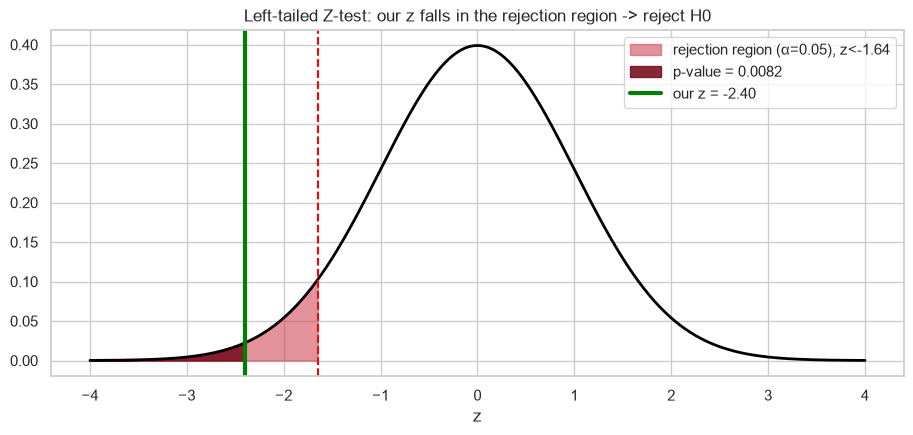

In [ ]:
# Visualise the decision
xs = np.linspace(-4, 4, 600)
curve = pd.DataFrame({"z": xs, "density": stats.norm.pdf(xs)})
crit = stats.norm.ppf(0.05)

plt.figure(figsize=(11, 4.5))
sns.lineplot(data=curve, x="z", y="density", color="black", lw=2)

rej = curve[curve["z"] <= crit]
plt.fill_between(rej["z"], rej["density"], color=RED, alpha=.6,
                 label=f"rejection region (α=0.05), z<{crit:.2f}")
pval_area = curve[curve["z"] <= z]
plt.fill_between(pval_area["z"], pval_area["density"], color="#7a1020", alpha=.9,
                 label=f"p-value = {p:.4f}")

plt.axvline(z, color=GREEN, lw=3, label=f"our z = {z:.2f}")
plt.axvline(crit, color=RED, ls="--")
plt.title("Left-tailed Z-test: our z falls in the rejection region -> reject H0")
plt.ylabel(""); plt.yticks([]); plt.legend(); plt.show()


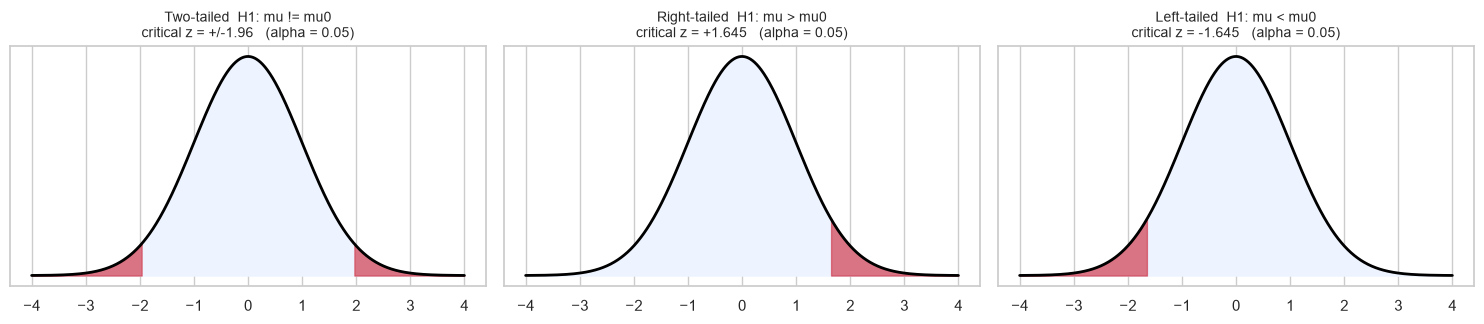

Two-tailed splits alpha into 2.5% + 2.5%, so the cut-off moves further out (1.96 > 1.645).


In [ ]:
# Two-tailed vs one-tailed: where does the 5% live?
xg = np.linspace(-4, 4, 800)
curve = pd.DataFrame({"z": xg, "density": stats.norm.pdf(xg)})

setups = [("Two-tailed  H1: mu != mu0", [(-4, -1.96), (1.96, 4)], "+/-1.96"),
          ("Right-tailed  H1: mu > mu0", [(1.645, 4)], "+1.645"),
          ("Left-tailed  H1: mu < mu0", [(-4, -1.645)], "-1.645")]

fig, axes = plt.subplots(1, 3, figsize=(15, 3.4))
for ax, (title, regions, lbl) in zip(axes, setups):
    sns.lineplot(data=curve, x="z", y="density", color="black", lw=2, ax=ax)
    plt.sca(ax)
    plt.fill_between(curve["z"], curve["density"], color="#eef4ff")
    for a_, b_ in regions:
        band = curve[curve["z"].between(a_, b_)]
        plt.fill_between(band["z"], band["density"], color=RED, alpha=.75)
    ax.set_title(f"{title}\ncritical z = {lbl}   (alpha = 0.05)", fontsize=10)
    ax.set_ylabel(""); ax.set_yticks([])
plt.tight_layout(); plt.show()

print("Two-tailed splits alpha into 2.5% + 2.5%, so the cut-off moves further out (1.96 > 1.645).")


### 7.2 Real test on the dataset
**Question:** Is the mean CGPA of our students different from the national benchmark of 7.0?

In [44]:
sample = df[col].dropna().sample(n=120, random_state=7)
res = one_sample_ztest(sample, mu0=7.0, alpha=0.05, tail="two", label="CGPA vs benchmark 7.0")

=== Z-TEST CGPA vs benchmark 7.0 ===
H0: mu = 7.0   |   H1: mu != 7.0   (two-tailed, alpha=0.05)
n = 120   x-bar = 8.2611   sigma = 1.1171   SE = 0.1020
z statistic     = 12.3661
critical value  = +/-1.960
p-value         = 0.000000
95% CI for mu  = [8.0612, 8.4610]
effect size (Cohen's d) = 1.1289
DECISION        : REJECT H0  (statistically significant)



In [45]:
# Same test using statsmodels (the library way)
try:
    from statsmodels.stats.weightstats import ztest
    zstat, pval = ztest(sample, value=7.0, alternative="two-sided")
    print(f"statsmodels ztest -> z={zstat:.4f}, p={pval:.6f}")
except ImportError:
    print("statsmodels not installed. Run:  pip install statsmodels")

statsmodels not installed. Run:  pip install statsmodels


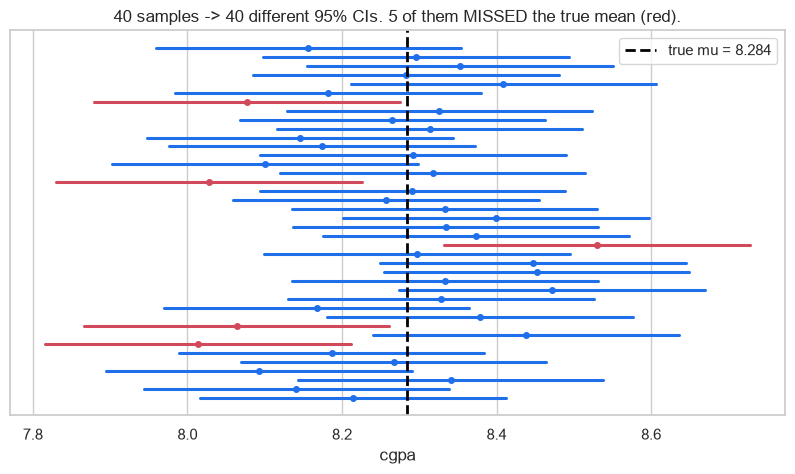

The PROCEDURE is 95% reliable - not any single interval you happen to compute.


In [ ]:
# What does "95% confidence" actually mean? Draw 40 samples, draw 40 intervals.
mu_true, sigma_, n_ci = POP_MEAN, POP_STD, 100
se_ci = sigma_ / np.sqrt(n_ci)

intervals = []
for i in range(40):
    xb = population[col].sample(n_ci, replace=True).mean()
    lo_, hi_ = xb - 1.96 * se_ci, xb + 1.96 * se_ci
    verdict = "contains μ" if lo_ <= mu_true <= hi_ else "MISSES μ"
    intervals += [{"trial": i, "cgpa": lo_, "centre": xb, "result": verdict},
                  {"trial": i, "cgpa": hi_, "centre": xb, "result": verdict}]
ci_df = pd.DataFrame(intervals)
palette = {"contains μ": BLUE, "MISSES μ": RED}
missed = ci_df.loc[ci_df["result"] == "MISSES μ", "trial"].nunique()

plt.figure(figsize=(10, 5))
sns.lineplot(data=ci_df, x="cgpa", y="trial", units="trial", estimator=None,
             hue="result", palette=palette, lw=2.2, orient="y")
sns.scatterplot(data=ci_df.drop_duplicates("trial"), x="centre", y="trial",
                hue="result", palette=palette, s=25, legend=False)
plt.axvline(mu_true, color="black", ls="--", lw=2, label=f"true mu = {mu_true:.3f}")
plt.yticks([]); plt.ylabel("")
plt.title(f"40 samples -> 40 different 95% CIs. {missed} of them MISSED the true mean (red).")
plt.legend(); plt.show()

print("The PROCEDURE is 95% reliable - not any single interval you happen to compute.")


### 7.3 Two-sample Z-test
**Question:** Do students **with internships** have a different mean CGPA than those **without**?

$$z=\frac{\bar{x}_1-\bar{x}_2}{\sqrt{\dfrac{s_1^2}{n_1}+\dfrac{s_2^2}{n_2}}}$$

In [46]:
def two_sample_ztest(a, b, alpha=0.05, names=("group A", "group B")):
    a, b = np.asarray(a, float), np.asarray(b, float)
    n1, n2 = len(a), len(b)
    m1, m2 = a.mean(), b.mean()
    v1, v2 = a.var(ddof=1), b.var(ddof=1)
    se = np.sqrt(v1/n1 + v2/n2)
    z = (m1 - m2) / se
    p = 2 * (1 - stats.norm.cdf(abs(z)))
    crit = stats.norm.ppf(1 - alpha/2)
    diff = m1 - m2
    ci = (diff - crit*se, diff + crit*se)

    print(f"H0: mu({names[0]}) = mu({names[1]})   |   H1: they differ   (two-tailed, alpha={alpha})")
    print(f"{names[0]}: n={n1}, mean={m1:.4f}, sd={np.sqrt(v1):.4f}")
    print(f"{names[1]}: n={n2}, mean={m2:.4f}, sd={np.sqrt(v2):.4f}")
    print(f"difference = {diff:+.4f}   SE = {se:.4f}")
    print(f"z = {z:.4f} | critical +/-{crit:.3f} | p = {p:.6f}")
    print(f"95% CI for the difference = [{ci[0]:+.4f}, {ci[1]:+.4f}]")
    print("DECISION:", "REJECT H0 - the groups really are different" if p < alpha
          else "FAIL TO REJECT H0 - difference could be chance")
    return z, p


g1 = df.loc[df["internships_completed"] > 0, col]
g2 = df.loc[df["internships_completed"] == 0, col]
two_sample_ztest(g1, g2, names=("with internship", "no internship"));

H0: mu(with internship) = mu(no internship)   |   H1: they differ   (two-tailed, alpha=0.05)
with internship: n=4572, mean=8.3915, sd=0.9474
no internship: n=428, mean=7.1329, sd=0.9191
difference = +1.2586   SE = 0.0466
z = 27.0174 | critical +/-1.960 | p = 0.000000
95% CI for the difference = [+1.1673, +1.3499]
DECISION: REJECT H0 - the groups really are different


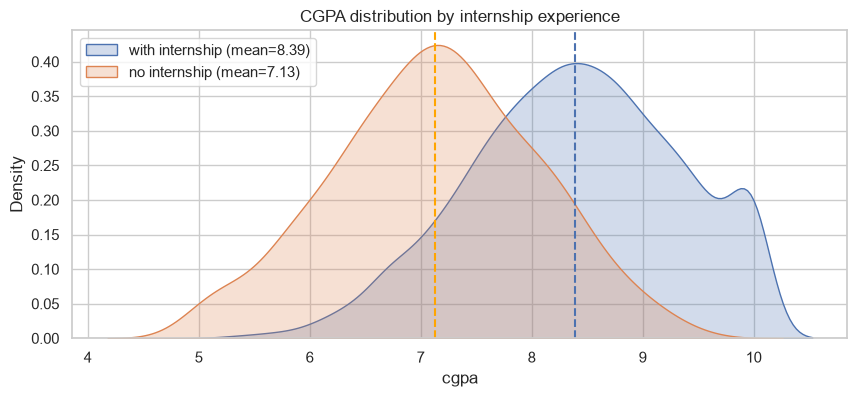

In [47]:
plt.figure(figsize=(10, 4))
sns.kdeplot(g1, fill=True, label=f"with internship (mean={g1.mean():.2f})")
sns.kdeplot(g2, fill=True, label=f"no internship (mean={g2.mean():.2f})")
plt.axvline(g1.mean(), ls="--"); plt.axvline(g2.mean(), ls="--", color="orange")
plt.title("CGPA distribution by internship experience"); plt.legend(); plt.show()

### 7.4 Z-test for a proportion
**Question:** A college claims **60%** of its students complete at least one internship. Does the data support that?

$$z=\frac{\hat p-p_0}{\sqrt{p_0(1-p_0)/n}}$$

In [48]:
successes = (df["internships_completed"] > 0).sum()
n_        = len(df)
p_hat     = successes / n_
p0        = 0.60

se = np.sqrt(p0 * (1 - p0) / n_)
z  = (p_hat - p0) / se
p  = 2 * (1 - stats.norm.cdf(abs(z)))

print(f"H0: p = {p0}   |   H1: p != {p0}")
print(f"observed p-hat = {p_hat:.4f}  ({successes}/{n_})")
print(f"SE = {se:.5f} | z = {z:.4f} | p-value = {p:.6f}")
print("DECISION:", "REJECT H0 - the claim is not supported" if p < 0.05 else "FAIL TO REJECT H0")

H0: p = 0.6   |   H1: p != 0.6
observed p-hat = 0.9144  (4572/5000)
SE = 0.00693 | z = 45.3797 | p-value = 0.000000
DECISION: REJECT H0 - the claim is not supported


### 7.5 Type I error — see the 5% false alarms with your own eyes
We run 1000 tests where **H₀ is TRUE by construction**. With α = 0.05 we should still reject about 5% of the time.

Rejected H0 in 52/1000 tests = 5.2%  (expected ~5% = alpha)
Those are TYPE I ERRORS - false positives we knowingly accept.


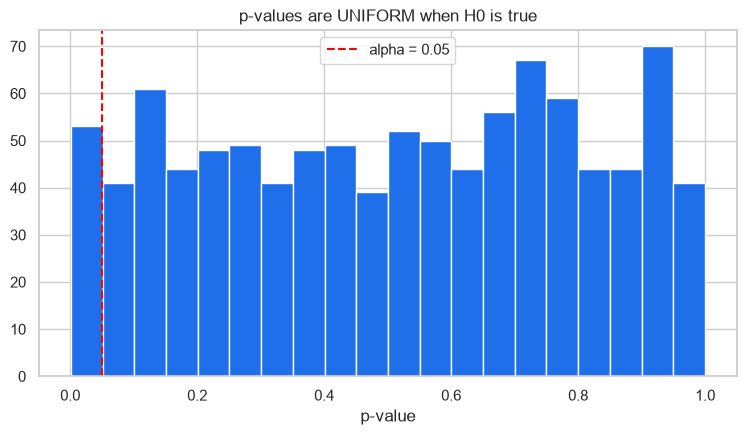

In [ ]:
true_mu, true_sigma, n_, alpha = 7.0, 0.8, 50, 0.05
rejections = 0
pvals = []
for _ in range(1000):
    s = np.random.normal(true_mu, true_sigma, n_)      # H0 is genuinely true
    zstat = (s.mean() - true_mu) / (true_sigma / np.sqrt(n_))
    pv = 2 * (1 - stats.norm.cdf(abs(zstat)))
    pvals.append(pv)
    rejections += pv < alpha

print(f"Rejected H0 in {rejections}/1000 tests = {rejections/10:.1f}%  (expected ~5% = alpha)")
print("Those are TYPE I ERRORS - false positives we knowingly accept.")

sns.histplot(x=pvals, bins=20, color=BLUE)
plt.axvline(0.05, color=RED, ls="--", label="alpha = 0.05")
plt.title("p-values are UNIFORM when H0 is true"); plt.xlabel("p-value"); plt.legend(); plt.show()


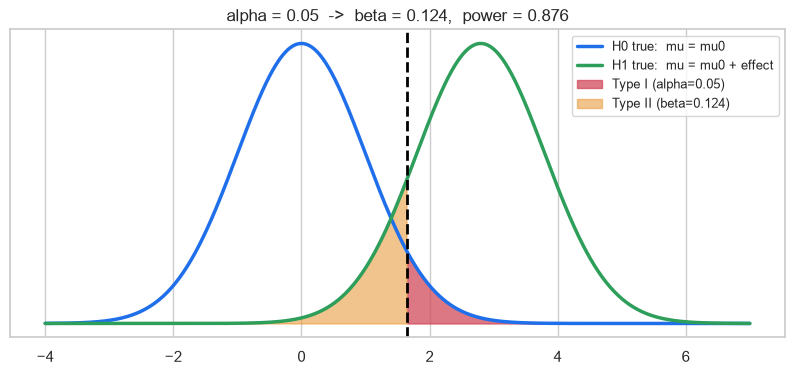

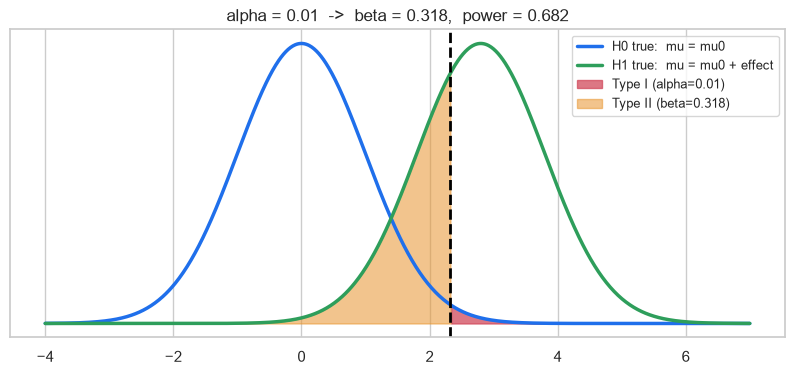

Lowering alpha shrinks Type I but grows Type II. The only way to shrink BOTH is a bigger n.


In [ ]:
# The alpha / beta trade-off, drawn
def error_tradeoff(effect=2.8, alpha=0.05):
    x = np.linspace(-4, 7, 900)
    curves = pd.DataFrame({
        "z": np.tile(x, 2),
        "density": np.concatenate([stats.norm.pdf(x, 0, 1), stats.norm.pdf(x, effect, 1)]),
        "hypothesis": ["H0 true:  mu = mu0"] * len(x) + ["H1 true:  mu = mu0 + effect"] * len(x),
    })
    crit_ = stats.norm.ppf(1 - alpha)
    beta = stats.norm.cdf(crit_, effect, 1)

    plt.figure(figsize=(10, 4))
    sns.lineplot(data=curves, x="z", y="density", hue="hypothesis",
                 palette=[BLUE, GREEN], lw=2.5)

    h0 = curves[curves["hypothesis"].str.startswith("H0")]
    h1 = curves[curves["hypothesis"].str.startswith("H1")]
    a_area = h0[h0["z"] >= crit_]
    b_area = h1[h1["z"] <= crit_]
    plt.fill_between(a_area["z"], a_area["density"], color=RED, alpha=.75,
                     label=f"Type I (alpha={alpha:.2f})")
    plt.fill_between(b_area["z"], b_area["density"], color=ORANGE, alpha=.55,
                     label=f"Type II (beta={beta:.3f})")

    plt.axvline(crit_, color="black", ls="--", lw=2)
    plt.ylabel(""); plt.yticks([])
    plt.title(f"alpha = {alpha:.2f}  ->  beta = {beta:.3f},  power = {1-beta:.3f}")
    plt.legend(fontsize=9); plt.show()


error_tradeoff(alpha=0.05)
error_tradeoff(alpha=0.01)   # stricter alpha -> less red, but MUCH more orange
print("Lowering alpha shrinks Type I but grows Type II. The only way to shrink BOTH is a bigger n.")


### 7.6 Statistical vs practical significance

In [50]:
# A tiny, meaningless difference of 0.02 CGPA - watch what n does to the p-value
true_effect, sigma_ = 0.02, 0.8
rows = []
for n_ in [30, 100, 1_000, 10_000, 100_000]:
    se = sigma_ / np.sqrt(n_)
    z = true_effect / se
    rows.append({"n": n_, "z": z, "p-value": 2*(1-stats.norm.cdf(abs(z))),
                 "significant?": "YES" if 2*(1-stats.norm.cdf(abs(z))) < 0.05 else "no",
                 "Cohen's d": true_effect/sigma_})
pd.DataFrame(rows)

,n,z,p-value,significant?,Cohen's d
0,30,0.137,0.891,no,0.025
1,100,0.250,0.803,no,0.025
2,1000,0.791,0.429,no,0.025
3,10000,2.500,0.012,YES,0.025
4,100000,7.906,0.000,YES,0.025


> ⚠️ The effect size (Cohen's d = 0.025, **negligible**) never changes — only the p-value does.
> **Always report effect size alongside the p-value.**

---
## 8. Solved Practice Questions

In [51]:
# Q1. Salaries (LPA): 3,4,4,5,6,40 -> mean or median?
sal = np.array([3, 4, 4, 5, 6, 40])
print(f"mean={sal.mean():.2f} LPA, median={np.median(sal):.2f} LPA")
print("Report the MEDIAN - 40 LPA is an outlier that inflates the mean.\n")

# Q2. mean=50, sd=5 -> range covering ~95%
print(f"Q2: 95% lies within 2 sigma -> [{50-2*5}, {50+2*5}]\n")

# Q3. Scores ~ N(70,10). % scoring above 85?
z3 = (85 - 70) / 10
print(f"Q3: z = {z3:.2f} -> P(X>85) = {(1-stats.norm.cdf(z3))*100:.2f}%\n")

# Q4. Different branch sizes -> STRATIFIED sampling
print("Q4: Stratified sampling - guarantees every branch is represented proportionally.\n")

# Q5. xbar=52, mu0=50, sigma=8, n=64, alpha=0.05, two-tailed
se5 = 8 / np.sqrt(64)
z5 = (52 - 50) / se5
p5 = 2 * (1 - stats.norm.cdf(abs(z5)))
print(f"Q5: SE={se5:.2f}, z={z5:.2f}, p={p5:.4f}, critical=+/-1.96")
print("    |z|=2.0 > 1.96 -> REJECT H0, the mean differs significantly from 50.\n")

# Q6. p=0.03 with alpha=0.01
print("Q6: 0.03 > 0.01 -> FAIL TO REJECT H0 at the 1% level.")
print("    (It WOULD have been significant at alpha=0.05 - the threshold matters!)")

mean=10.33 LPA, median=4.50 LPA
Report the MEDIAN - 40 LPA is an outlier that inflates the mean.

Q2: 95% lies within 2 sigma -> [40, 60]

Q3: z = 1.50 -> P(X>85) = 6.68%

Q4: Stratified sampling - guarantees every branch is represented proportionally.

Q5: SE=1.00, z=2.00, p=0.0455, critical=+/-1.96
    |z|=2.0 > 1.96 -> REJECT H0, the mean differs significantly from 50.

Q6: 0.03 > 0.01 -> FAIL TO REJECT H0 at the 1% level.
    (It WOULD have been significant at alpha=0.05 - the threshold matters!)


---
## 9. Mini project — your turn 🚀

Using this dataset, answer with full statistical reasoning:

1. **Descriptive:** Which branch has the highest median CGPA? The most consistent CGPA (lowest CV)?
2. **Distribution:** Is `study_hours_per_day` normally distributed? Use a histogram, Q-Q plot and Shapiro-Wilk.
3. **Z-score:** Build a `z_score_profile(student_id)` function that prints how a student compares to the class on 5 features.
4. **Sampling:** Draw a stratified sample by `city_tier` (10%) and compare its mean CGPA to the population.
5. **Hypothesis test:** Do students who do a `part_time_job` have a significantly lower CGPA? State H₀/H₁, run a two-sample Z-test, report p-value, CI and effect size.
6. **Write-up:** Summarise every conclusion in plain business English — no jargon.

> Deliverable: one clean notebook where every number is followed by a sentence explaining what it *means*.

In [52]:
# your project code here